# ĐỒ ÁN TRÍ TUỆ NHÂN TẠO: PHÂN LOẠI KIỂU THẢM RỪNG TỪ DỮ LIỆU ĐỊA HÌNH
## Forest Cover Type Classification (UCI Dataset ID: 31)

**Mô tả**: Phân loại 7 kiểu thảm rừng ôn đới núi cao tại Rừng quốc gia Roosevelt (Colorado, Hoa Kỳ) bằng **Random Forest**, kết hợp **lấy mẫu phân tầng**, **kỹ thuật tạo đặc trưng sinh thái** và các thí nghiệm phân tích triệt tiêu (ablation) theo [KE_HOACH_THI_NGHIEM.md](../docs/02_ke_hoach_va_kien_truc/KE_HOACH_THI_NGHIEM.md).

**Dữ liệu**: 581.012 ô lưới 30 m × 30 m, 54 thuộc tính trắc địa và thổ nhưỡng, 7 lớp mục tiêu.

### Mục lục
| Bước | Nội dung | Thí nghiệm |
| :---: | :--- | :--- |
| 1 | Môi trường, cấu hình, hàm dùng chung | |
| 2 | Nạp và thẩm tra dữ liệu | |
| 3 | Phân tích khám phá (EDA) | |
| 4 | Phân chia dữ liệu và mẫu khảo sát 15% | |
| 5 | Hàm tạo đặc trưng sinh thái | |
| 6 | Thí nghiệm trên mẫu khảo sát: trọng số lớp, đặc trưng, thổ nhưỡng | E0, E1, E2, E3 |
| 7 | Quy mô dữ liệu huấn luyện | E4 |
| 8 | Tinh chỉnh siêu tham số | E5 |
| 9 | Mô hình cuối: huấn luyện, chốt số cây, lưu | |
| 10 | Đánh giá một lần trên D_final | |
| 11 | Tổng quát hoá sang vùng chưa thấy | E6 |
| 12 | Tổng kết, hạn chế, đầu vào cho Bước trích xuất luật | |

**Quy tắc ra quyết định dùng xuyên suốt** (mục 2.2 và 5 của kế hoạch thí nghiệm):
1. Mọi so sánh cấu hình dùng **D_val**, lặp **3 seed**, báo cáo trung bình ± độ lệch chuẩn (SD).
2. Chênh lệch nhỏ hơn 1 SD của cấu hình tốt nhất được coi là **không khác biệt có ý nghĩa**; khi đó chọn cấu hình **đơn giản hơn** (ít cột hơn, hoặc ít nút hơn).
3. **D_final** chỉ dùng **một lần**, sau khi đã chốt toàn bộ cấu hình.

---
# BƯỚC 1: MÔI TRƯỜNG, CẤU HÌNH VÀ HÀM DÙNG CHUNG

In [1]:
# === THƯ VIỆN ===
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path
from IPython.display import display
import warnings, time, os, sys, gc, json
import psutil
import joblib
from scipy.stats import chi2

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, f1_score, precision_score, recall_score)
from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 220)
pd.set_option('display.float_format', '{:.4f}'.format)
plt.rcParams.update({'figure.figsize': (12, 6), 'figure.dpi': 100, 'font.size': 11,
                     'axes.titlesize': 13, 'axes.labelsize': 12})
sns.set_theme(style='whitegrid', palette='deep')

print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | Matplotlib {plt.matplotlib.__version__} | seaborn {sns.__version__}")
print(f"CPU: {os.cpu_count()} lõi | RAM: {psutil.virtual_memory().total / 2**30:.1f} GB")

Python 3.13.5 | NumPy 2.5.4 | pandas 3.1.1 | scikit-learn 1.9.1 | Matplotlib 3.11.2 | seaborn 0.13.2
CPU: 24 lõi | RAM: 15.8 GB


In [2]:
# === CẤU HÌNH THÍ NGHIỆM ===
RANDOM_STATE = 42
SEEDS = [42, 7, 2024]        # 3 seed cho mọi so sánh cấu hình
EVAL_FRACTION = 0.20         # D_final và D_val, mỗi tập 20% toàn bộ dữ liệu
EXPLORE_FRACTION = 0.15      # mẫu khảo sát (Bước 6): 15% toàn bộ dữ liệu, rút phân tầng từ D_pool
N_EST_EXP = 100              # số cây trong các thí nghiệm so sánh
N_EST_MAX = 300              # số cây tối đa của mô hình cuối (Bước 9)
MEM_BUDGET_GB = 3.0          # ngân sách bộ nhớ cho mô hình cuối
BYTES_PER_NODE = 64 + 7 * 8  # ước lượng: struct Node của sklearn + mảng value (7 lớp, float64)
np.random.seed(RANDOM_STATE)

CLASS_NAMES = {1: 'Spruce/Fir', 2: 'Lodgepole Pine', 3: 'Ponderosa Pine', 4: 'Cottonwood/Willow',
               5: 'Aspen', 6: 'Douglas-fir', 7: 'Krummholz'}
SHORT_NAMES = ['Spruce/\nFir', 'Lodgepole\nPine', 'Ponderosa\nPine', 'Cotton./\nWillow',
               'Aspen', 'Douglas-\nfir', 'Krumm-\nholz']
TARGET_NAMES = [f"Lớp {i} ({CLASS_NAMES[i]})" for i in range(1, 8)]
WA_NAMES = {1: 'Rawah', 2: 'Neota', 3: 'Comanche Peak', 4: 'Cache la Poudre'}


# === ĐƯỜNG DẪN DỰ ÁN ===
# Notebook nằm trong notebooks/. Tìm thư mục gốc (chứa docs/ và notebooks/) để chạy được
# từ gốc dự án, từ notebooks/, hoặc trên Colab sau khi clone repo.
def _find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / 'docs').is_dir() and (p / 'notebooks').is_dir():
            return p
    return start


PROJECT_ROOT = _find_project_root(Path.cwd().resolve())
DATA_DIR = PROJECT_ROOT / 'data' / 'raw'
MODEL_DIR = PROJECT_ROOT / 'models'
FIG_DIR = PROJECT_ROOT / 'results' / 'figures'
TABLE_DIR = PROJECT_ROOT / 'results' / 'tables'
for _d in (DATA_DIR, MODEL_DIR, FIG_DIR, TABLE_DIR):
    _d.mkdir(parents=True, exist_ok=True)
print(f"Thư mục dự án: {PROJECT_ROOT}")

Thư mục dự án: D:\Git_Repo\Forest Cover Type Classification


In [3]:
# === HÀM DÙNG CHUNG ===
def wilson_ci(k, n, z=1.96):
    """Khoảng tin cậy Wilson 95% cho tỷ lệ k/n."""
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    margin = z * np.sqrt((p * (1 - p) + z**2 / (4 * n)) / n) / denom
    return (max(0.0, center - margin), min(1.0, center + margin))


def eval_preds(y_true, y_pred):
    """Accuracy, Macro-F1, Recall từng lớp, Precision lớp 4."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    rec = recall_score(y_true, y_pred, average=None, labels=range(1, 8), zero_division=0)
    prec = precision_score(y_true, y_pred, average=None, labels=range(1, 8), zero_division=0)
    out = {'accuracy': accuracy_score(y_true, y_pred),
           'macro_f1': f1_score(y_true, y_pred, average='macro'),
           'precision_c4': prec[3]}
    for c in range(1, 8):
        out[f'recall_c{c}'] = rec[c - 1]
    return out


def n_nodes(rf):
    return int(sum(e.tree_.node_count for e in rf.estimators_))


def rss_gb():
    return psutil.Process().memory_info().rss / 2**30


def fit_eval(X_tr, y_tr, X_ev, y_ev, params, seed):
    """Huấn luyện một RF, đánh giá trên tập so sánh, giải phóng mô hình."""
    rf = RandomForestClassifier(random_state=seed, n_jobs=-1, **params)
    t0 = time.time()
    rf.fit(X_tr, y_tr)
    row = {'seed': seed, 'n_train': len(y_tr), 'n_features': X_tr.shape[1],
           'fit_s': time.time() - t0, **eval_preds(y_ev, rf.predict(X_ev)), 'nodes': n_nodes(rf)}
    del rf
    gc.collect()
    return row


def summarize(df, by):
    """Trung bình ± SD qua các seed."""
    return (df.groupby(by, sort=False)
            .agg(n_features=('n_features', 'first'), n_train=('n_train', 'first'),
                 f1_mean=('macro_f1', 'mean'), f1_sd=('macro_f1', 'std'),
                 acc_mean=('accuracy', 'mean'),
                 rc4_mean=('recall_c4', 'mean'), rc4_sd=('recall_c4', 'std'), prec_c4=('precision_c4', 'mean'),
                 rc5_mean=('recall_c5', 'mean'), rc6_mean=('recall_c6', 'mean'),
                 nodes=('nodes', 'mean'), fit_s=('fit_s', 'mean'))
            .reset_index())


def choose_simplest(summary, key, simplicity):
    """Quy tắc ra quyết định: trong các cấu hình có F1 TB ≥ (F1 tốt nhất − 1 SD), chọn cấu hình
    có giá trị `simplicity` nhỏ nhất (ít cột / ít nút). In ra lập luận và trả về hàng được chọn."""
    best = summary.loc[summary['f1_mean'].idxmax()]
    thr = best['f1_mean'] - best['f1_sd']
    cand = summary[summary['f1_mean'] >= thr].sort_values([simplicity, 'f1_mean'], ascending=[True, False])
    chosen = cand.iloc[0]
    print(f"Tốt nhất theo F1: {best[key]} ({best['f1_mean']:.4f} ± {best['f1_sd']:.4f}) → ngưỡng {thr:.4f}")
    print(f"Ứng viên trong ngưỡng: {cand[key].tolist()}")
    print(f"→ Chọn (ít {simplicity} nhất): {chosen[key]}  (F1 = {chosen['f1_mean']:.4f} ± {chosen['f1_sd']:.4f})")
    return chosen


print("✓ Đã khai báo hàm dùng chung.")

✓ Đã khai báo hàm dùng chung.


---
# BƯỚC 2: NẠP VÀ THẨM TRA DỮ LIỆU
> Thứ tự nguồn: `data/raw/covtype.data` → `data/raw/covtype.data.gz` → `sklearn.datasets.fetch_covtype()`. Bản tải qua scikit-learn đã được đối chiếu và trùng khớp từng giá trị, cùng thứ tự dòng với file UCI, nên các phép chia theo `random_state` cho cùng kết quả.

In [4]:
RAW_FEATURES = ['Elevation', 'Aspect', 'Slope',
                'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology',
                'Horizontal_Distance_To_Roadways',
                'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm',
                'Horizontal_Distance_To_Fire_Points'] \
               + [f'Wilderness_Area_{i}' for i in range(1, 5)] \
               + [f'Soil_Type_{i}' for i in range(1, 41)]
COL_NAMES = RAW_FEATURES + ['Cover_Type']

DATA_PATH, GZ_PATH = DATA_DIR / 'covtype.data', DATA_DIR / 'covtype.data.gz'
if DATA_PATH.exists():
    print(f"Đọc dữ liệu từ: {DATA_PATH}")
    df_raw = pd.read_csv(DATA_PATH, header=None, names=COL_NAMES)
elif GZ_PATH.exists():
    print(f"Đọc dữ liệu từ: {GZ_PATH}")
    df_raw = pd.read_csv(GZ_PATH, header=None, names=COL_NAMES, compression='gzip')
else:
    from sklearn.datasets import fetch_covtype
    print("Không thấy file cục bộ → tải UCI Covertype qua sklearn.datasets.fetch_covtype()")
    _cov = fetch_covtype(as_frame=False)
    df_raw = pd.DataFrame(np.column_stack([_cov.data, _cov.target]).astype(np.int64), columns=COL_NAMES)
print(f"Kích thước: {df_raw.shape[0]:,} dòng × {df_raw.shape[1]} cột")

Đọc dữ liệu từ: D:\Git_Repo\Forest Cover Type Classification\data\raw\covtype.data
Kích thước: 581,012 dòng × 55 cột


In [5]:
# === THẨM TRA TOÀN VẸN ===
EXPECTED_COUNTS = {1: 211840, 2: 283301, 3: 35754, 4: 2747, 5: 9493, 6: 17367, 7: 20510}
assert df_raw.shape == (581012, 55), f"Kích thước {df_raw.shape} ≠ (581012, 55)"
assert df_raw.isnull().sum().sum() == 0, "Có giá trị thiếu"
counts = df_raw['Cover_Type'].value_counts().sort_index()
assert counts.to_dict() == EXPECTED_COUNTS, "Phân bố lớp không khớp covtype.info"
assert (df_raw[[f'Wilderness_Area_{i}' for i in range(1, 5)]].sum(axis=1) == 1).all(), "Wilderness one-hot lỗi"
assert (df_raw[[f'Soil_Type_{i}' for i in range(1, 41)]].sum(axis=1) == 1).all(), "Soil one-hot lỗi"
print("✓ 581.012 × 55, 0 giá trị thiếu, phân bố 7 lớp khớp covtype.info, one-hot Wilderness/Soil hợp lệ.")

# === ÉP KIỂU ĐỂ GIẢM RAM ===
mem_before = df_raw.memory_usage(deep=True).sum() / 2**20
binary_cols = [c for c in RAW_FEATURES if c.startswith(('Wilderness_Area', 'Soil_Type'))]
df_raw[binary_cols] = df_raw[binary_cols].astype(np.uint8)
df_raw['Cover_Type'] = df_raw['Cover_Type'].astype(np.uint8)
numeric_cols = [c for c in RAW_FEATURES if c not in binary_cols]
df_raw[numeric_cols] = df_raw[numeric_cols].astype(np.int32)
print(f"RAM DataFrame: {mem_before:.1f} MB → {df_raw.memory_usage(deep=True).sum() / 2**20:.1f} MB")

# Mã vùng hoang dã (dùng cho EDA và E6, không đưa vào mô hình)
wa_code = pd.Series(df_raw[[f'Wilderness_Area_{i}' for i in range(1, 5)]].values.argmax(axis=1) + 1,
                    index=df_raw.index, name='Wilderness')

✓ 581.012 × 55, 0 giá trị thiếu, phân bố 7 lớp khớp covtype.info, one-hot Wilderness/Soil hợp lệ.
RAM DataFrame: 243.8 MB → 47.1 MB


---
# BƯỚC 3: PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (EDA)
> Mục tiêu: định lượng mất cân bằng lớp, đối chiếu phân bố cao độ với các đai sinh thái trong văn liệu (Peet 1981, Marr 1961), xác minh quy ước dấu của `Vertical_Distance_To_Hydrology`, khảo sát tương quan và phân bố lớp theo vùng hoang dã.

## 3.1. Phân bố 7 kiểu thảm rừng và mức độ mất cân bằng

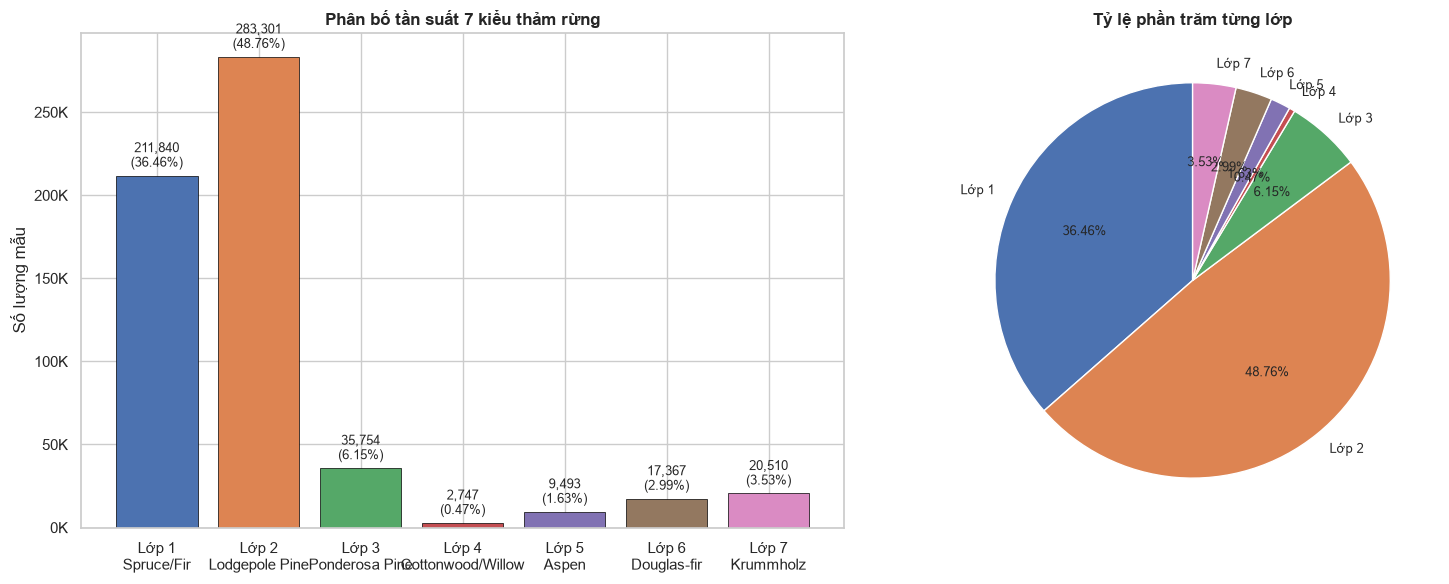

Hai lớp đa số (1+2): 495,141 mẫu (85.22%)
Lớp thiểu số (4):    2,747 mẫu (0.473%)
Tỷ số đa số / thiểu số: 180 : 1


In [6]:
class_counts = df_raw['Cover_Type'].value_counts().sort_index()
colors = sns.color_palette('deep', 7)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
bars = axes[0].bar([f"Lớp {i}\n{CLASS_NAMES[i]}" for i in range(1, 8)], class_counts.values,
                   color=colors, edgecolor='black', linewidth=0.5)
for bar, cnt in zip(bars, class_counts.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 3000,
                 f'{cnt:,}\n({cnt / len(df_raw) * 100:.2f}%)', ha='center', va='bottom', fontsize=9)
axes[0].set_title('Phân bố tần suất 7 kiểu thảm rừng', fontweight='bold')
axes[0].set_ylabel('Số lượng mẫu')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x / 1000:.0f}K'))
axes[1].pie(class_counts.values, labels=[f"Lớp {i}" for i in range(1, 8)], autopct='%1.2f%%',
            colors=colors, startangle=90, textprops={'fontsize': 9})
axes[1].set_title('Tỷ lệ phần trăm từng lớp', fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

majority, minority = class_counts[1] + class_counts[2], class_counts[4]
print(f"Hai lớp đa số (1+2): {majority:,} mẫu ({majority / len(df_raw) * 100:.2f}%)")
print(f"Lớp thiểu số (4):    {minority:,} mẫu ({minority / len(df_raw) * 100:.3f}%)")
print(f"Tỷ số đa số / thiểu số: {majority / minority:.0f} : 1")

## 3.2. Phân bố cao độ theo kiểu rừng — đối chiếu đai sinh thái

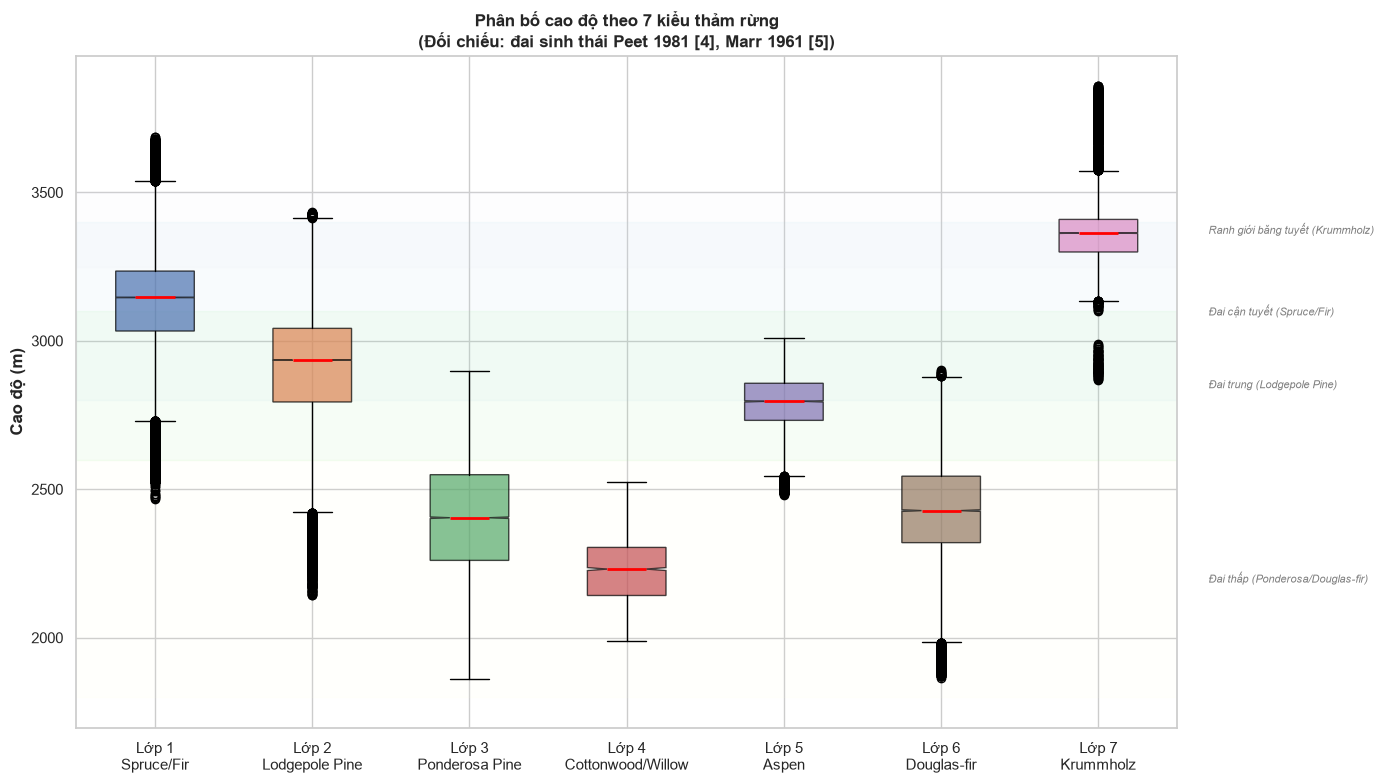

,mean,std,min,25%,50%,75%,max
Lớp 1 (Spruce/Fir),3128.6449,157.8055,2466.0000,3033.0000,3146.0000,3235.0000,3686.0000
Lớp 2 (Lodgepole Pine),2920.9361,186.5794,2142.0000,2794.0000,2935.0000,3042.0000,3433.0000
Lớp 3 (Ponderosa Pine),2394.5098,196.7324,1859.0000,2260.2500,2404.0000,2549.0000,2899.0000
Lớp 4 (Cottonwood/Willow),2223.9399,102.5246,1988.0000,2142.0000,2231.0000,2304.0000,2526.0000
Lớp 5 (Aspen),2787.4176,96.5940,2482.0000,2732.0000,2796.0000,2857.0000,3011.0000
Lớp 6 (Douglas-fir),2419.1819,188.7623,1863.0000,2320.0000,2428.0000,2544.0000,2900.0000
Lớp 7 (Krummholz),3361.9287,106.9153,2868.0000,3299.2500,3363.0000,3409.0000,3858.0000


In [7]:
fig, ax = plt.subplots(figsize=(14, 8))
bp = ax.boxplot([df_raw.loc[df_raw['Cover_Type'] == i, 'Elevation'].values for i in range(1, 8)],
                tick_labels=[f"Lớp {i}\n{CLASS_NAMES[i]}" for i in range(1, 8)],
                patch_artist=True, notch=True, medianprops=dict(color='red', linewidth=2))
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
for ymin, ymax, label, fcolor in [(1800, 2600, 'Đai thấp (Ponderosa/Douglas-fir)', 'lightyellow'),
                                  (2600, 3100, 'Đai trung (Lodgepole Pine)', 'lightgreen'),
                                  (2800, 3400, 'Đai cận tuyết (Spruce/Fir)', 'lightblue'),
                                  (3250, 3500, 'Ranh giới băng tuyết (Krummholz)', 'lavender')]:
    ax.axhspan(ymin, ymax, alpha=0.08, color=fcolor)
    ax.text(7.7, (ymin + ymax) / 2, label, fontsize=8, va='center', fontstyle='italic', color='gray')
ax.set_ylabel('Cao độ (m)', fontweight='bold')
ax.set_title('Phân bố cao độ theo 7 kiểu thảm rừng\n(Đối chiếu: đai sinh thái Peet 1981 [4], Marr 1961 [5])',
             fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_elevation_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()

elev_stats = df_raw.groupby('Cover_Type')['Elevation'].describe()
elev_stats.index = TARGET_NAMES
display(elev_stats[['mean', 'std', 'min', '25%', '50%', '75%', 'max']])

## 3.3. Quy ước dấu của `Vertical_Distance_To_Hydrology`

Min -173 | Max 601 | TB 46.42 | Trung vị 30.0
  Số mẫu < 0: 55,143 (9.5%)
  Số mẫu = 0: 38,665 (6.7%)
  Số mẫu > 0: 487,204 (83.9%)


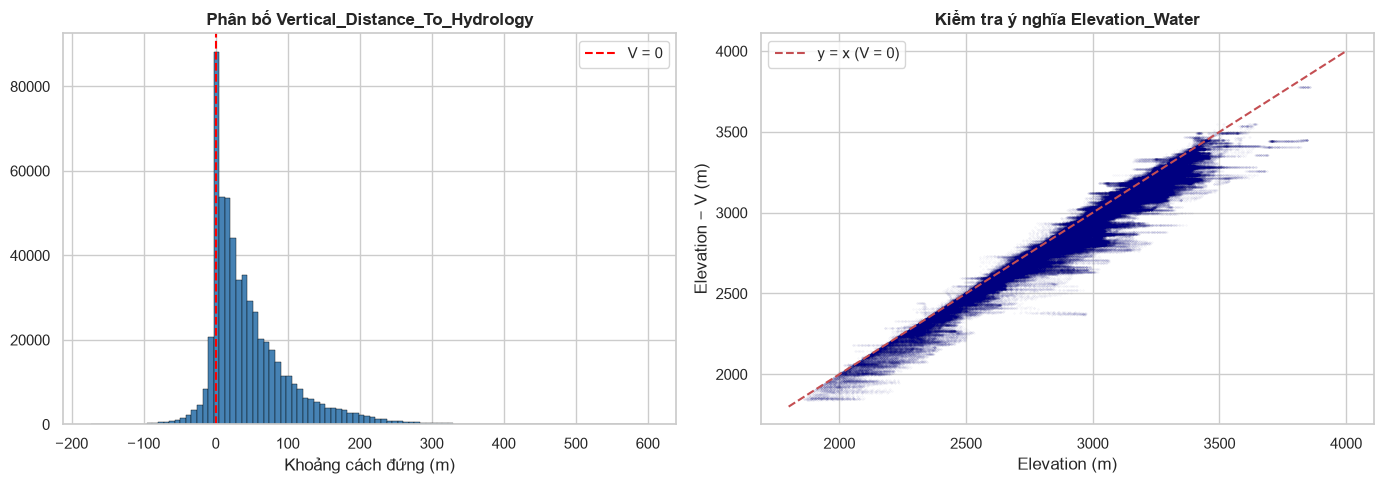

Diễn giải: V > 0 ⟹ điểm đo cao hơn nguồn nước (trên sườn); V < 0 ⟹ thấp hơn nguồn nước.
Elevation_Water = Elevation − V là cao độ của nguồn nước mặt gần nhất.


In [8]:
vdth = df_raw['Vertical_Distance_To_Hydrology']
print(f"Min {vdth.min()} | Max {vdth.max()} | TB {vdth.mean():.2f} | Trung vị {vdth.median():.1f}")
for lbl, mask in [('< 0', vdth < 0), ('= 0', vdth == 0), ('> 0', vdth > 0)]:
    print(f"  Số mẫu {lbl}: {mask.sum():,} ({mask.mean() * 100:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(vdth, bins=100, edgecolor='black', linewidth=0.3, color='steelblue')
axes[0].axvline(0, color='red', linestyle='--', label='V = 0')
axes[0].set_title('Phân bố Vertical_Distance_To_Hydrology', fontweight='bold')
axes[0].set_xlabel('Khoảng cách đứng (m)')
axes[0].legend()
axes[1].scatter(df_raw['Elevation'], df_raw['Elevation'] - vdth, s=0.05, alpha=0.1, c='navy')
axes[1].plot([1800, 4000], [1800, 4000], 'r--', label='y = x (V = 0)')
axes[1].set_xlabel('Elevation (m)')
axes[1].set_ylabel('Elevation − V (m)')
axes[1].set_title('Kiểm tra ý nghĩa Elevation_Water', fontweight='bold')
axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_vertical_distance.png', dpi=150, bbox_inches='tight')
plt.show()
print("Diễn giải: V > 0 ⟹ điểm đo cao hơn nguồn nước (trên sườn); V < 0 ⟹ thấp hơn nguồn nước.")
print("Elevation_Water = Elevation − V là cao độ của nguồn nước mặt gần nhất.")

## 3.4. Tương quan giữa các biến trắc địa liên tục

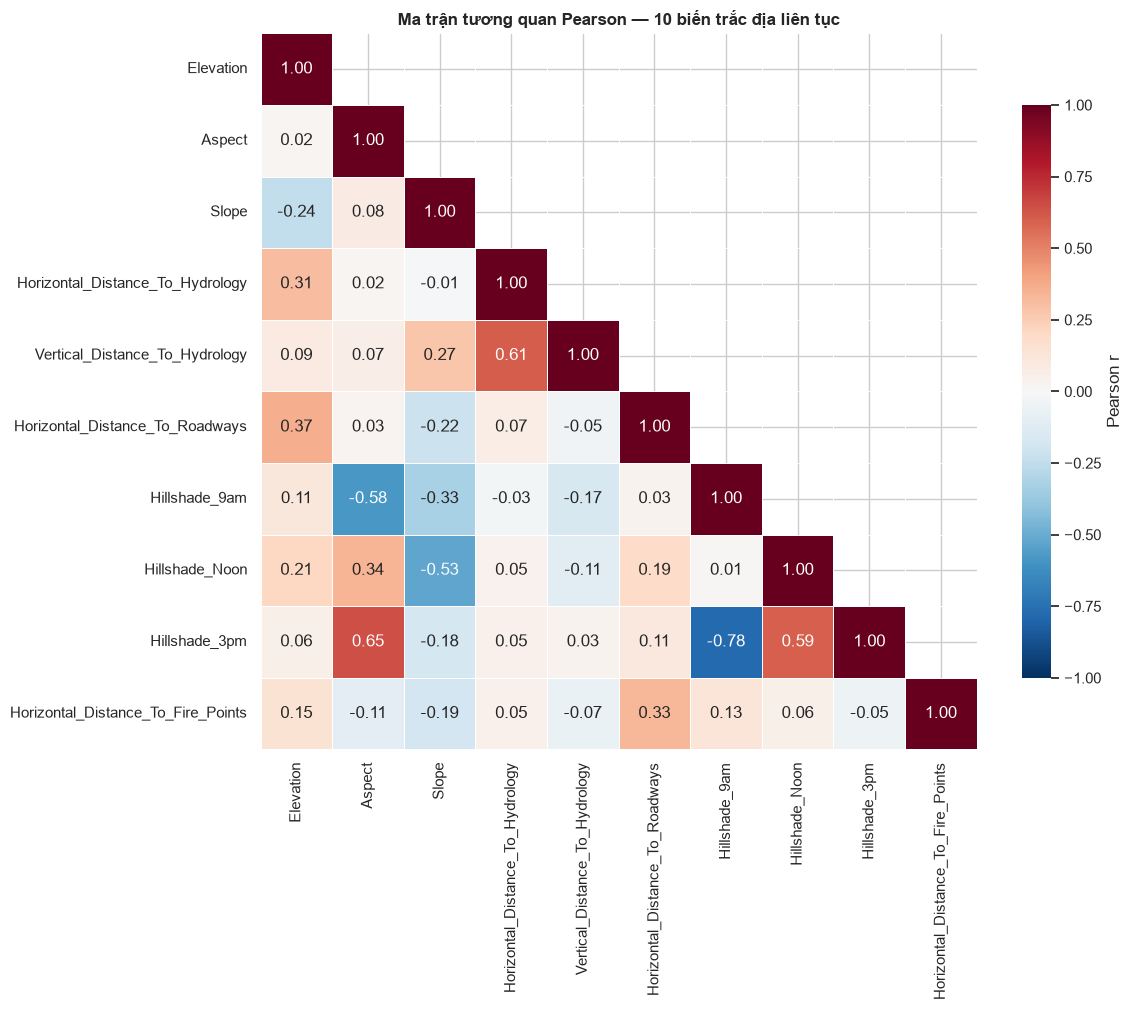

Các cặp |r| > 0,5:
                                Aspect ↔ Hillshade_9am                        r = -0.579
                                Aspect ↔ Hillshade_3pm                        r = +0.647
                                 Slope ↔ Hillshade_Noon                       r = -0.527
      Horizontal_Distance_To_Hydrology ↔ Vertical_Distance_To_Hydrology       r = +0.606
                         Hillshade_9am ↔ Hillshade_3pm                        r = -0.780
                        Hillshade_Noon ↔ Hillshade_3pm                        r = +0.594


In [9]:
continuous_cols = RAW_FEATURES[:10]
corr = df_raw[continuous_cols].corr()
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax,
            cbar_kws={'shrink': 0.8, 'label': 'Pearson r'})
ax.set_title('Ma trận tương quan Pearson — 10 biến trắc địa liên tục', fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("Các cặp |r| > 0,5:")
for i in range(len(continuous_cols)):
    for j in range(i + 1, len(continuous_cols)):
        if abs(corr.iloc[i, j]) > 0.5:
            print(f"  {continuous_cols[i]:>36s} ↔ {continuous_cols[j]:<36s} r = {corr.iloc[i, j]:+.3f}")

## 3.5. Phân bố kiểu rừng theo vùng hoang dã (Wilderness Area)

Wilderness,WA1 (Rawah),WA2 (Neota),WA3 (Comanche Peak),WA4 (Cache la Poudre),Tổng
Cover_Type,,,,,
Lớp 1 (Spruce/Fir),105717,18595,87528,0,211840
Lớp 2 (Lodgepole Pine),146197,8985,125093,3026,283301
Lớp 3 (Ponderosa Pine),0,0,14300,21454,35754
Lớp 4 (Cottonwood/Willow),0,0,0,2747,2747
Lớp 5 (Aspen),3781,0,5712,0,9493
Lớp 6 (Douglas-fir),0,0,7626,9741,17367
Lớp 7 (Krummholz),5101,2304,13105,0,20510
Tổng,260796,29884,253364,36968,581012


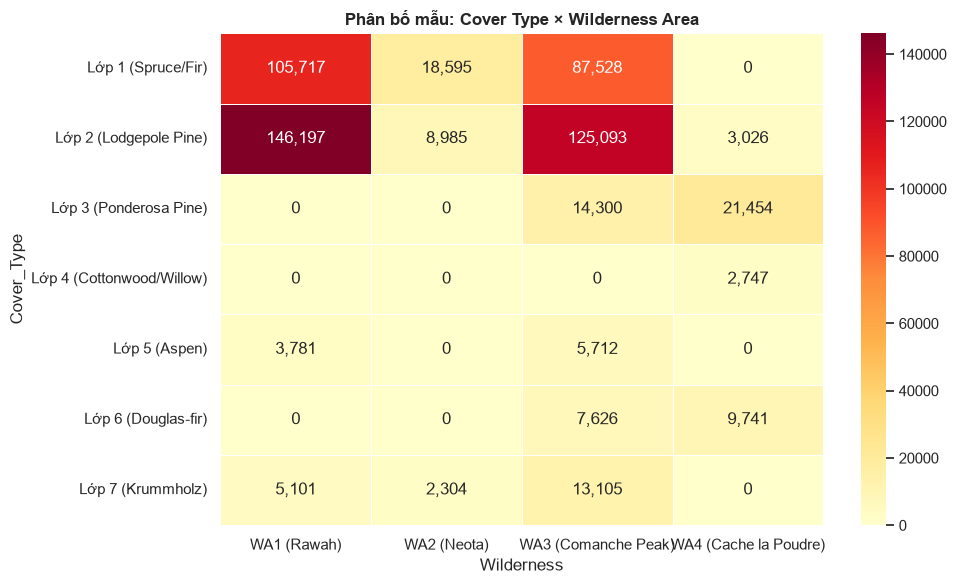

Các vùng có mặt từng lớp: {1: [np.int64(1), np.int64(2), np.int64(3)], 2: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)], 3: [np.int64(3), np.int64(4)], 4: [np.int64(4)], 5: [np.int64(1), np.int64(3)], 6: [np.int64(3), np.int64(4)], 7: [np.int64(1), np.int64(2), np.int64(3)]}
Lưu ý cho E6: lớp nào chỉ có ở một vùng sẽ không có mẫu huấn luyện khi vùng đó bị bỏ ra.


In [10]:
ct = pd.crosstab(df_raw['Cover_Type'].map(lambda x: f"Lớp {x} ({CLASS_NAMES[x]})"),
                 wa_code.map(lambda x: f"WA{x} ({WA_NAMES[x]})"), margins=True, margins_name='Tổng')
display(ct)
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(ct.iloc[:-1, :-1].astype(int), annot=True, fmt=',', cmap='YlOrRd', ax=ax, linewidths=0.5)
ax.set_title('Phân bố mẫu: Cover Type × Wilderness Area', fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_crosstab_wa.png', dpi=150, bbox_inches='tight')
plt.show()
only_in = {c: sorted(wa_code[df_raw['Cover_Type'] == c].unique()) for c in range(1, 8)}
print("Các vùng có mặt từng lớp:", {c: v for c, v in only_in.items()})
print("Lưu ý cho E6: lớp nào chỉ có ở một vùng sẽ không có mẫu huấn luyện khi vùng đó bị bỏ ra.")

---
# BƯỚC 4: PHÂN CHIA DỮ LIỆU VÀ MẪU KHẢO SÁT 15%

| Tập | Cách tạo | Quy mô xấp xỉ | Vai trò |
| :--- | :--- | :---: | :--- |
| **D_final** | 20% toàn bộ, phân tầng theo nhãn | 116.202 (lớp 4 ≈ 549) | Đánh giá **một lần** ở Bước 10; đo Fidelity của cây đại diện ở bước trích xuất luật |
| **D_val** | 20% toàn bộ, phân tầng | 116.202 (lớp 4 ≈ 549) | So sánh cấu hình ở E0–E5; sau khi chốt: bể truy vấn cho cây đại diện |
| **D_pool** | 60% còn lại | 348.608 | Bể huấn luyện |
| **Mẫu khảo sát S15** | 15% toàn bộ dữ liệu, rút phân tầng **từ D_pool** | 87.152 | Huấn luyện ở E0–E3 (pha khảo sát nhanh) |

**Lý do**:
- Lấy mẫu phân tầng giữ nguyên tỷ lệ 7 lớp ở mọi tập ([CHIEN_LUOC_LAY_MAU_PHAN_TANG.md](../docs/03_co_so_ly_thuyet/CHIEN_LUOC_LAY_MAU_PHAN_TANG.md)).
- D_val đủ lớn để Recall lớp 4 có khoảng tin cậy hẹp (≈ 549 mẫu).
- Mẫu khảo sát S15 cho phép chạy nhiều cấu hình ở E0–E3 với chi phí thấp. Việc mẫu 15% làm mất bao nhiêu hiệu năng được đo riêng ở E4.

**Hạn chế**: chia ngẫu nhiên theo dòng, nên các ô 30 m liền kề có thể rơi vào cả tập huấn luyện lẫn tập đánh giá (tự tương quan không gian). E6 kiểm tra ảnh hưởng này bằng cách bỏ ra từng vùng hoang dã.

In [11]:
X_all = df_raw[RAW_FEATURES]
y_all = df_raw['Cover_Type']
N_EVAL = int(round(EVAL_FRACTION * len(df_raw)))

X_rest, X_final_raw, y_rest, y_final = train_test_split(
    X_all, y_all, test_size=N_EVAL, stratify=y_all, random_state=RANDOM_STATE)
X_pool_raw, X_val_raw, y_pool, y_val = train_test_split(
    X_rest, y_rest, test_size=N_EVAL, stratify=y_rest, random_state=RANDOM_STATE)

N_EXPLORE = int(round(EXPLORE_FRACTION * len(df_raw)))
idx_explore, _ = train_test_split(np.arange(len(y_pool)), train_size=N_EXPLORE,
                                  stratify=y_pool, random_state=RANDOM_STATE)
idx_explore = np.sort(idx_explore)
X_s15_raw, y_s15 = X_pool_raw.iloc[idx_explore], y_pool.iloc[idx_explore]

# Kiểm tra tính rời nhau
_f, _v, _p = set(X_final_raw.index), set(X_val_raw.index), set(X_pool_raw.index)
assert _f.isdisjoint(_v) and _f.isdisjoint(_p) and _v.isdisjoint(_p)
assert len(_f) + len(_v) + len(_p) == len(df_raw)
print("✓ D_final, D_val, D_pool rời nhau và phủ toàn bộ dữ liệu; S15 ⊂ D_pool.")

split_tbl = pd.DataFrame({
    'Toàn bộ': y_all.value_counts().sort_index(),
    'D_final': y_final.value_counts().sort_index(),
    'D_val': y_val.value_counts().sort_index(),
    'D_pool': y_pool.value_counts().sort_index(),
    'S15': y_s15.value_counts().sort_index(),
})
split_pct = split_tbl / split_tbl.sum() * 100
split_tbl.index = TARGET_NAMES
split_tbl.loc['Tổng'] = split_tbl.sum()
display(split_tbl)
print(f"Độ lệch tỷ lệ lớp lớn nhất so với toàn bộ: "
      f"{(split_pct.sub(split_pct['Toàn bộ'], axis=0)).abs().values.max():.4f} điểm phần trăm")

✓ D_final, D_val, D_pool rời nhau và phủ toàn bộ dữ liệu; S15 ⊂ D_pool.


,Toàn bộ,D_final,D_val,D_pool,S15
Lớp 1 (Spruce/Fir),211840,42368,42368,127104,31776
Lớp 2 (Lodgepole Pine),283301,56660,56660,169981,42495
Lớp 3 (Ponderosa Pine),35754,7151,7151,21452,5363
Lớp 4 (Cottonwood/Willow),2747,549,550,1648,412
Lớp 5 (Aspen),9493,1899,1898,5696,1424
Lớp 6 (Douglas-fir),17367,3473,3473,10421,2605
Lớp 7 (Krummholz),20510,4102,4102,12306,3077
Tổng,581012,116202,116202,348608,87152


Độ lệch tỷ lệ lớp lớn nhất so với toàn bộ: 0.0006 điểm phần trăm


---
# BƯỚC 5: HÀM TẠO ĐẶC TRƯNG SINH THÁI
> Một hàm `build_features()` dùng chung cho mọi tập (D_pool, D_val, D_final, hàm tương tác sau này), nên mọi tập đi qua cùng một phép biến đổi. Cơ sở lý thuyết: [KY_THUAT_TAO_DAC_TRUNG_SINH_THAI.md](../docs/03_co_so_ly_thuyet/KY_THUAT_TAO_DAC_TRUNG_SINH_THAI.md).

| Nhóm | Cột | Định nghĩa |
| :--- | :--- | :--- |
| `D_Hydro` | `D_Hydro` | $\sqrt{H^2 + V^2}$, khoảng cách Euclid tới nguồn nước mặt gần nhất |
| `Elevation_Water` | `Elevation_Water` | Elevation − V, cao độ của nguồn nước mặt gần nhất |
| `Aspect_Trig` | `Aspect_Cos`, `Aspect_Sin` | Biến đổi lượng giác của hướng sườn (biến tuần hoàn) |
| `Delta_Hillshade` | `Delta_Hillshade` | Hillshade_3pm − Hillshade_9am |
| `dist_combo` | 6 cột | Tổng và \|hiệu\| từng cặp trong 3 khoảng cách ngang (Hydrology, Roadways, Fire_Points). Heuristic thực hành, **chưa có cơ sở bình duyệt** |
| Thổ nhưỡng | — | `onehot` (40 cột gốc), `code` (1 cột mã 1–40), `zone` (vùng khí hậu + địa chất theo USFS ELU), `code_zone` (cả hai) |

In [12]:
SOIL_COLS = [f'Soil_Type_{i}' for i in range(1, 41)]
SOIL_TO_ELU = {
    1: 2702, 2: 2703, 3: 2704, 4: 2705, 5: 2706, 6: 2717, 7: 3501, 8: 3502, 9: 4201, 10: 4703,
    11: 4704, 12: 4744, 13: 4758, 14: 5101, 15: 5151, 16: 6101, 17: 6102, 18: 6731, 19: 7101, 20: 7102,
    21: 7103, 22: 7201, 23: 7202, 24: 7700, 25: 7701, 26: 7702, 27: 7709, 28: 7710, 29: 7745, 30: 7746,
    31: 7755, 32: 7756, 33: 7757, 34: 7790, 35: 8703, 36: 8707, 37: 8708, 38: 8771, 39: 8772, 40: 8776,
}
CLIMATIC_LUT = np.array([0] + [int(str(SOIL_TO_ELU[k])[0]) for k in range(1, 41)], dtype=np.uint8)
GEOLOGIC_LUT = np.array([0] + [int(str(SOIL_TO_ELU[k])[1]) for k in range(1, 41)], dtype=np.uint8)
ECO_GROUPS = ('D_Hydro', 'Elevation_Water', 'Aspect_Trig', 'Delta_Hillshade')


def build_features(df, eco=ECO_GROUPS, soil='onehot', dist_combo=False):
    """Tạo ma trận đặc trưng (float32) từ 54 cột gốc.

    eco        : các nhóm đặc trưng sinh thái cần thêm (tập con của ECO_GROUPS)
    soil       : 'onehot' | 'code' | 'zone' | 'code_zone'
    dist_combo : thêm 6 cột tổ hợp khoảng cách ngang
    """
    out = df[RAW_FEATURES].astype(np.float32)
    H = out['Horizontal_Distance_To_Hydrology']
    V = out['Vertical_Distance_To_Hydrology']
    if 'D_Hydro' in eco:
        out['D_Hydro'] = np.sqrt(H ** 2 + V ** 2)
    if 'Elevation_Water' in eco:
        out['Elevation_Water'] = out['Elevation'] - V
    if 'Aspect_Trig' in eco:
        rad = np.deg2rad(out['Aspect'])
        out['Aspect_Cos'], out['Aspect_Sin'] = np.cos(rad), np.sin(rad)
    if 'Delta_Hillshade' in eco:
        out['Delta_Hillshade'] = out['Hillshade_3pm'] - out['Hillshade_9am']
    if dist_combo:
        Hr = out['Horizontal_Distance_To_Roadways']
        Hf = out['Horizontal_Distance_To_Fire_Points']
        out['Hydro_Fire_Sum'], out['Hydro_Fire_Diff'] = H + Hf, (H - Hf).abs()
        out['Hydro_Road_Sum'], out['Hydro_Road_Diff'] = H + Hr, (H - Hr).abs()
        out['Fire_Road_Sum'], out['Fire_Road_Diff'] = Hf + Hr, (Hf - Hr).abs()
    if soil != 'onehot':
        code_ = df[SOIL_COLS].values.argmax(axis=1) + 1
        out = out.drop(columns=SOIL_COLS)
        if soil in ('code', 'code_zone'):
            out['Soil_Type_Code'] = code_.astype(np.float32)
        if soil in ('zone', 'code_zone'):
            out['Soil_Climatic_Zone'] = CLIMATIC_LUT[code_].astype(np.float32)
            out['Soil_Geologic_Zone'] = GEOLOGIC_LUT[code_].astype(np.float32)
        elif soil not in ('code',):
            raise ValueError(f"soil không hợp lệ: {soil}")
    return out.astype(np.float32)


# Kiểm tra nhanh trên vài dòng
_demo = build_features(X_val_raw.head(1000), soil='code_zone', dist_combo=True)
assert not _demo.isnull().any().any()
print(f"✓ build_features() sẵn sàng. Ví dụ đầy đủ nhất: {_demo.shape[1]} cột")
print("  ", _demo.columns.tolist())

✓ build_features() sẵn sàng. Ví dụ đầy đủ nhất: 28 cột
   ['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways', 'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points', 'Wilderness_Area_1', 'Wilderness_Area_2', 'Wilderness_Area_3', 'Wilderness_Area_4', 'D_Hydro', 'Elevation_Water', 'Aspect_Cos', 'Aspect_Sin', 'Delta_Hillshade', 'Hydro_Fire_Sum', 'Hydro_Fire_Diff', 'Hydro_Road_Sum', 'Hydro_Road_Diff', 'Fire_Road_Sum', 'Fire_Road_Diff', 'Soil_Type_Code', 'Soil_Climatic_Zone', 'Soil_Geologic_Zone']


---
# BƯỚC 6: THÍ NGHIỆM TRÊN MẪU KHẢO SÁT S15 (E0–E3)
> Huấn luyện trên S15 (87.152 mẫu), đánh giá trên D_val, `n_estimators = 100`, các siêu tham số khác giữ mặc định của scikit-learn (`max_depth=None`, `max_features='sqrt'`). Mỗi thí nghiệm chốt một quyết định và chuyển sang thí nghiệm sau. Siêu tham số được tinh chỉnh riêng ở E5.

## 6.1. E0 + E1: Baseline và trọng số lớp
> **E0** là RF trên 54 cột gốc, `class_weight=None`. **E1** so sánh `class_weight` ∈ {None, `balanced`, `balanced_subsample`}. Ngoài Macro-F1, Recall và Precision của lớp 4 được theo dõi riêng, vì trọng số lớp có thể tăng Recall nhưng giảm Precision.
>
> **Quy tắc chọn**: trong ngưỡng 1 SD, chọn cấu hình ít nút nhất.

In [13]:
exp_rows = []          # toàn bộ kết quả E0–E3, lưu ra CSV ở cuối Bước 6
X_s15_base = build_features(X_s15_raw, eco=(), soil='onehot')
X_val_base = build_features(X_val_raw, eco=(), soil='onehot')

for cw in [None, 'balanced', 'balanced_subsample']:
    label = 'E0: class_weight=None' if cw is None else f'E1: class_weight={cw}'
    for seed in SEEDS:
        exp_rows.append({'exp': 'E0/E1', 'config': label, 'class_weight': cw,
                         **fit_eval(X_s15_base, y_s15, X_val_base, y_val,
                                    {'n_estimators': N_EST_EXP, 'class_weight': cw}, seed)})

e1_sum = summarize(pd.DataFrame([r for r in exp_rows if r['exp'] == 'E0/E1']), 'config')
display(e1_sum)
e1_choice = choose_simplest(e1_sum, 'config', 'nodes')
CW = {'E0: class_weight=None': None}.get(e1_choice['config'], e1_choice['config'].split('=')[1])
print(f"\n→ class_weight dùng cho E2–E4: {CW!r}")
del X_s15_base, X_val_base

,config,n_features,n_train,f1_mean,f1_sd,acc_mean,rc4_mean,rc4_sd,prec_c4,rc5_mean,rc6_mean,nodes,fit_s
0,E0: class_weight=None,54,87152,0.8432,0.0019,0.9047,0.7576,0.0042,0.8362,0.5509,0.7487,2453472.6667,1.9290
1,E1: class_weight=balanced,54,87152,0.8471,0.0012,0.8891,0.7642,0.0042,0.8178,0.7912,0.8299,1720906.6667,1.4016
2,E1: class_weight=balanced_subsample,54,87152,0.8412,0.0012,0.9065,0.7339,0.0038,0.8227,0.5588,0.7344,2784072.0000,1.9725


Tốt nhất theo F1: E1: class_weight=balanced (0.8471 ± 0.0012) → ngưỡng 0.8459
Ứng viên trong ngưỡng: ['E1: class_weight=balanced']
→ Chọn (ít nodes nhất): E1: class_weight=balanced  (F1 = 0.8471 ± 0.0012)

→ class_weight dùng cho E2–E4: 'balanced'


## 6.2. E2: Đặc trưng sinh thái
> So sánh: 54 cột gốc; gốc + toàn bộ 4 nhóm sinh thái; bỏ lần lượt từng nhóm; gốc + 4 nhóm + tổ hợp khoảng cách. Thổ nhưỡng giữ dạng One-Hot (biểu diễn đất được so sánh ở E3).
>
> **Quy tắc chọn**: trong ngưỡng 1 SD, chọn phương án ít cột nhất. Lý do: mỗi cột thêm vào đều có thể xuất hiện trong luật của cây đại diện, nên cột chỉ được giữ khi có cải thiện đo được.

In [14]:
E2_VARIANTS = {'Gốc (54 cột)': dict(eco=(), dist_combo=False),
               'Gốc + 4 nhóm sinh thái': dict(eco=ECO_GROUPS, dist_combo=False)}
for g in ECO_GROUPS:
    E2_VARIANTS[f'Bỏ {g}'] = dict(eco=tuple(x for x in ECO_GROUPS if x != g), dist_combo=False)
E2_VARIANTS['4 nhóm + tổ hợp khoảng cách'] = dict(eco=ECO_GROUPS, dist_combo=True)

for name, spec in E2_VARIANTS.items():
    Xtr = build_features(X_s15_raw, soil='onehot', **spec)
    Xev = build_features(X_val_raw, soil='onehot', **spec)
    for seed in SEEDS:
        exp_rows.append({'exp': 'E2', 'config': name,
                         **fit_eval(Xtr, y_s15, Xev, y_val, {'n_estimators': N_EST_EXP, 'class_weight': CW}, seed)})
    del Xtr, Xev
    print(f"  xong: {name}")

e2_sum = summarize(pd.DataFrame([r for r in exp_rows if r['exp'] == 'E2']), 'config')
base_f1 = e2_sum.loc[e2_sum['config'] == 'Gốc + 4 nhóm sinh thái', 'f1_mean'].iloc[0]
e2_sum['ΔF1 so với 4 nhóm'] = e2_sum['f1_mean'] - base_f1
display(e2_sum)
e2_choice = choose_simplest(e2_sum, 'config', 'n_features')
FEATURE_SPEC = {**E2_VARIANTS[e2_choice['config']]}
print(f"\n→ Đặc trưng sinh thái dùng tiếp: eco={FEATURE_SPEC['eco']}, dist_combo={FEATURE_SPEC['dist_combo']}")

  xong: Gốc (54 cột)
  xong: Gốc + 4 nhóm sinh thái
  xong: Bỏ D_Hydro
  xong: Bỏ Elevation_Water
  xong: Bỏ Aspect_Trig
  xong: Bỏ Delta_Hillshade
  xong: 4 nhóm + tổ hợp khoảng cách


,config,n_features,n_train,f1_mean,f1_sd,acc_mean,rc4_mean,rc4_sd,prec_c4,rc5_mean,rc6_mean,nodes,fit_s,ΔF1 so với 4 nhóm
0,Gốc (54 cột),54,87152,0.8471,0.0012,0.8891,0.7642,0.0042,0.8178,0.7912,0.8299,1720906.6667,1.3681,-0.0028
1,Gốc + 4 nhóm sinh thái,59,87152,0.8499,0.0015,0.8856,0.7976,0.0084,0.8297,0.7894,0.8252,1618529.3333,1.4540,0.0000
2,Bỏ D_Hydro,58,87152,0.8502,0.0009,0.8853,0.7921,0.0056,0.8427,0.7914,0.8270,1641751.3333,1.4045,0.0003
3,Bỏ Elevation_Water,58,87152,0.8332,0.0005,0.8766,0.7552,0.0021,0.8123,0.7636,0.7975,1749962.0000,1.4460,-0.0167
4,Bỏ Aspect_Trig,57,87152,0.8557,0.0011,0.8920,0.7933,0.0038,0.8301,0.8051,0.8391,1598668.6667,1.3971,0.0058
5,Bỏ Delta_Hillshade,58,87152,0.8532,0.0006,0.8889,0.7933,0.0028,0.8301,0.7956,0.8336,1612889.3333,1.4035,0.0033
6,4 nhóm + tổ hợp khoảng cách,65,87152,0.8901,0.0019,0.9216,0.8206,0.0042,0.8527,0.8621,0.8926,1243126.0000,1.7127,0.0402


Tốt nhất theo F1: 4 nhóm + tổ hợp khoảng cách (0.8901 ± 0.0019) → ngưỡng 0.8881
Ứng viên trong ngưỡng: ['4 nhóm + tổ hợp khoảng cách']
→ Chọn (ít n_features nhất): 4 nhóm + tổ hợp khoảng cách  (F1 = 0.8901 ± 0.0019)

→ Đặc trưng sinh thái dùng tiếp: eco=('D_Hydro', 'Elevation_Water', 'Aspect_Trig', 'Delta_Hillshade'), dist_combo=True


## 6.3. E3: Biểu diễn thổ nhưỡng
> **Giả thuyết "pha loãng"**: 40 cột One-Hot chiếm phần lớn số chiều, nên với `max_features='sqrt'` các biến địa hình ít được xét tại mỗi nút. So sánh (A) One-Hot, (B) `Soil_Type_Code`, (C) vùng khí hậu + địa chất, (D) Code + Zones.
>
> **Quy tắc chọn**: trong ngưỡng 1 SD, chọn phương án ít cột nhất.

In [15]:
for soil in ['onehot', 'code', 'zone', 'code_zone']:
    Xtr = build_features(X_s15_raw, soil=soil, **FEATURE_SPEC)
    Xev = build_features(X_val_raw, soil=soil, **FEATURE_SPEC)
    for seed in SEEDS:
        exp_rows.append({'exp': 'E3', 'config': soil,
                         **fit_eval(Xtr, y_s15, Xev, y_val, {'n_estimators': N_EST_EXP, 'class_weight': CW}, seed)})
    del Xtr, Xev

e3_sum = summarize(pd.DataFrame([r for r in exp_rows if r['exp'] == 'E3']), 'config')
display(e3_sum)
e3_choice = choose_simplest(e3_sum, 'config', 'n_features')
FEATURE_SPEC['soil'] = e3_choice['config']
print(f"\n→ Tập đặc trưng sau E0–E3: {FEATURE_SPEC}")

pd.DataFrame(exp_rows).to_csv(TABLE_DIR / 'e0_e3_explore.csv', index=False, encoding='utf-8-sig')

,config,n_features,n_train,f1_mean,f1_sd,acc_mean,rc4_mean,rc4_sd,prec_c4,rc5_mean,rc6_mean,nodes,fit_s
0,onehot,65,87152,0.8901,0.0019,0.9216,0.8206,0.0042,0.8527,0.8621,0.8926,1243126.0000,1.7381
1,code,26,87152,0.8862,0.0004,0.9207,0.7958,0.0052,0.8477,0.8655,0.8908,1070018.6667,1.9110
2,zone,27,87152,0.8852,0.0016,0.9191,0.8067,0.0073,0.8419,0.8634,0.8913,1092106.6667,1.8771
3,code_zone,28,87152,0.8867,0.0007,0.9208,0.8073,0.0048,0.8479,0.8653,0.8916,1079838.0000,1.8527


Tốt nhất theo F1: onehot (0.8901 ± 0.0019) → ngưỡng 0.8881
Ứng viên trong ngưỡng: ['onehot']
→ Chọn (ít n_features nhất): onehot  (F1 = 0.8901 ± 0.0019)

→ Tập đặc trưng sau E0–E3: {'eco': ('D_Hydro', 'Elevation_Water', 'Aspect_Trig', 'Delta_Hillshade'), 'dist_combo': True, 'soil': 'onehot'}


---
# BƯỚC 7: E4 — QUY MÔ DỮ LIỆU HUẤN LUYỆN
> **Câu hỏi**: mẫu khảo sát 15% làm mất bao nhiêu hiệu năng so với dùng nhiều dữ liệu hơn? Huấn luyện trên 5% / 10% / 25% / 50% / 75% / 100% của D_pool (25% D_pool ≈ quy mô S15) với `max_depth` ∈ {20, None}, 3 seed, đánh giá trên D_val.
>
> **Quy tắc chọn**: với mỗi `max_depth`, chọn mức dữ liệu **nhỏ nhất** có F1 TB ≥ (F1 tốt nhất − 1 SD); sau đó chọn `max_depth` có F1 cao hơn tại mức đã chọn. Số nút được ghi lại vì kích thước rừng ảnh hưởng tới RAM và chi phí truy vấn ở bước trích xuất luật.

In [16]:
X_pool = build_features(X_pool_raw, **FEATURE_SPEC)
X_val = build_features(X_val_raw, **FEATURE_SPEC)
FEATURES = X_pool.columns.tolist()
E4_FRACS = [0.05, 0.10, 0.25, 0.50, 0.75, 1.00]
E4_DEPTHS = [20, None]


def pool_subset_idx(frac, seed):
    if frac >= 1.0:
        return np.arange(len(y_pool))
    idx, _ = train_test_split(np.arange(len(y_pool)), train_size=frac, stratify=y_pool, random_state=seed)
    return np.sort(idx)


e4_rows = []
t0 = time.time()
for frac in E4_FRACS:
    for seed in SEEDS:
        idx = pool_subset_idx(frac, seed)
        for depth in E4_DEPTHS:
            r = fit_eval(X_pool.iloc[idx], y_pool.iloc[idx], X_val, y_val,
                         {'n_estimators': N_EST_EXP, 'max_depth': depth, 'class_weight': CW}, seed)
            e4_rows.append({'frac': frac, 'max_depth': str(depth), **r, 'rss_gb': rss_gb()})
    print(f"  xong frac={frac:.2f} ({time.time() - t0:.0f}s)")

e4_df = pd.DataFrame(e4_rows)
e4_df.to_csv(TABLE_DIR / 'e4_learning_curve.csv', index=False, encoding='utf-8-sig')
e4_sum = summarize(e4_df, ['max_depth', 'frac'])
display(e4_sum)

  xong frac=0.05 (6s)
  xong frac=0.10 (14s)
  xong frac=0.25 (28s)
  xong frac=0.50 (61s)
  xong frac=0.75 (117s)
  xong frac=1.00 (195s)


,max_depth,frac,n_features,n_train,f1_mean,f1_sd,acc_mean,rc4_mean,rc4_sd,prec_c4,rc5_mean,rc6_mean,nodes,fit_s
0,20,0.0500,65,17430,0.7723,0.0078,0.8330,0.6564,0.0322,0.7866,0.7129,0.7310,320776.0000,0.4323
1,None,0.0500,65,17430,0.7843,0.0032,0.8408,0.6685,0.0211,0.7873,0.6630,0.7233,352596.0000,0.4470
2,20,0.1000,65,34860,0.8170,0.0046,0.8628,0.7339,0.0164,0.8471,0.8084,0.8275,523552.0000,0.6651
3,None,0.1000,65,34860,0.8341,0.0049,0.8761,0.7291,0.0200,0.8510,0.7460,0.8094,619565.3333,0.6796
4,20,0.2500,65,87152,0.8604,0.0047,0.8995,0.8364,0.0101,0.8508,0.9055,0.9000,940623.3333,1.6200
5,None,0.2500,65,87152,0.8896,0.0015,0.9201,0.8194,0.0110,0.8620,0.8614,0.8869,1242709.3333,1.6988
6,20,0.5000,65,174304,0.8835,0.0008,0.9197,0.8764,0.0036,0.8664,0.9468,0.9320,1379038.6667,4.6749
7,None,0.5000,65,174304,0.9191,0.0020,0.9446,0.8533,0.0086,0.8895,0.9087,0.9270,2037449.3333,4.8099
8,20,0.7500,65,261456,0.8924,0.0020,0.9289,0.8945,0.0119,0.8709,0.9612,0.9459,1697836.0000,8.3701
9,None,0.7500,65,261456,0.9313,0.0012,0.9551,0.8697,0.0121,0.8942,0.9312,0.9417,2673556.0000,8.6657


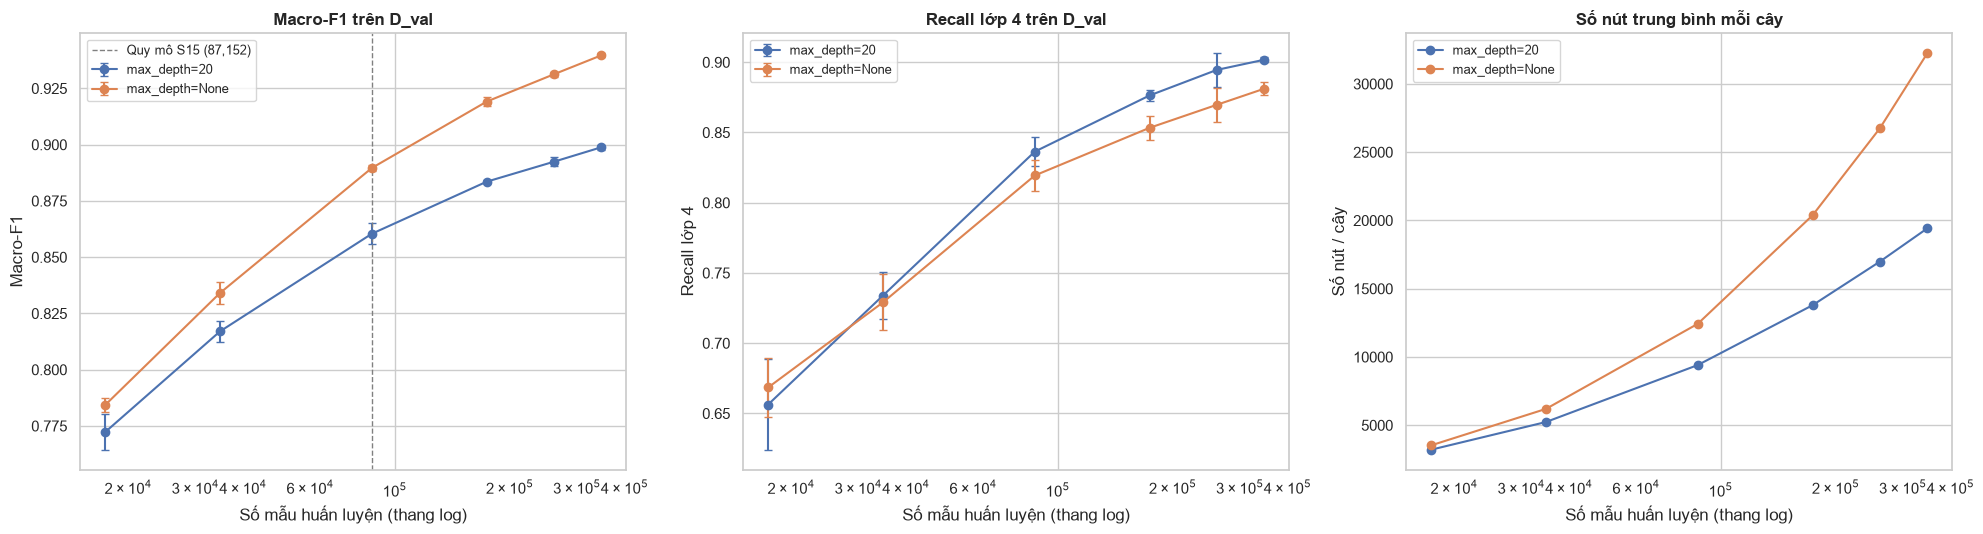

max_depth=20   : tốt nhất frac=1.00 (F1=0.8989 ± 0.0011); chọn frac=1.00 (F1=0.8989)
max_depth=None : tốt nhất frac=1.00 (F1=0.9397 ± 0.0009); chọn frac=1.00 (F1=0.9397)

→ Quy mô huấn luyện: 100% D_pool (n = 348,608); max_depth = None
  Chênh lệch Macro-F1 so với mức 25% D_pool (≈ S15), cùng max_depth: +0.0501


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for depth, grp in e4_sum.groupby('max_depth', sort=False):
    lbl = f"max_depth={depth}"
    axes[0].errorbar(grp['n_train'], grp['f1_mean'], yerr=grp['f1_sd'], marker='o', capsize=3, label=lbl)
    axes[1].errorbar(grp['n_train'], grp['rc4_mean'], yerr=grp['rc4_sd'], marker='o', capsize=3, label=lbl)
    axes[2].plot(grp['n_train'], grp['nodes'] / N_EST_EXP, marker='o', label=lbl)
axes[0].axvline(N_EXPLORE, color='gray', ls='--', lw=1, label=f'Quy mô S15 ({N_EXPLORE:,})')
for ax, title, ylab in zip(axes, ['Macro-F1 trên D_val', 'Recall lớp 4 trên D_val', 'Số nút trung bình mỗi cây'],
                           ['Macro-F1', 'Recall lớp 4', 'Số nút / cây']):
    ax.set_xscale('log')
    ax.set_xlabel('Số mẫu huấn luyện (thang log)')
    ax.set_ylabel(ylab)
    ax.set_title(title, fontweight='bold')
    ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / 'e4_learning_curve.png', dpi=150, bbox_inches='tight')
plt.show()

e4_choice = {}
for depth, grp in e4_sum.groupby('max_depth', sort=False):
    best = grp.loc[grp['f1_mean'].idxmax()]
    thr = best['f1_mean'] - best['f1_sd']
    e4_choice[depth] = grp[grp['f1_mean'] >= thr].sort_values('frac').iloc[0]
    print(f"max_depth={depth:<5}: tốt nhất frac={best['frac']:.2f} (F1={best['f1_mean']:.4f} ± {best['f1_sd']:.4f}); "
          f"chọn frac={e4_choice[depth]['frac']:.2f} (F1={e4_choice[depth]['f1_mean']:.4f})")
best_depth = max(e4_choice, key=lambda d: e4_choice[d]['f1_mean'])
TRAIN_FRAC = float(e4_choice[best_depth]['frac'])
MAX_DEPTH = None if best_depth == 'None' else int(best_depth)
idx_train = pool_subset_idx(TRAIN_FRAC, RANDOM_STATE)
X_tr, y_tr = X_pool.iloc[idx_train], y_pool.iloc[idx_train]
s15_ref = e4_sum[(e4_sum['frac'] == 0.25) & (e4_sum['max_depth'] == best_depth)]['f1_mean'].iloc[0]
print(f"\n→ Quy mô huấn luyện: {TRAIN_FRAC:.0%} D_pool (n = {len(y_tr):,}); max_depth = {MAX_DEPTH}")
print(f"  Chênh lệch Macro-F1 so với mức 25% D_pool (≈ S15), cùng max_depth: {e4_choice[best_depth]['f1_mean'] - s15_ref:+.4f}")

---
# BƯỚC 8: E5 — TINH CHỈNH SIÊU THAM SỐ
> Huấn luyện ở quy mô đã chọn ở E4, đánh giá trên D_val, `n_estimators = 100` (số cây được chốt riêng ở Bước 9).
> - **Giai đoạn 1**: `max_features` ∈ {sqrt, 0.35, 0.5, 0.7} × `criterion` ∈ {gini, entropy}; seed 42.
> - **Giai đoạn 2**: cấu hình tốt nhất giai đoạn 1 × `min_samples_leaf` ∈ {1, 2, 4} × `class_weight` ∈ {None, `balanced_subsample`, lựa chọn của E1}; seed 42.
> - **Giai đoạn 3**: 3 cấu hình đứng đầu, lặp đủ 3 seed.
>
> **Quy tắc chọn**: trong ngưỡng 1 SD, chọn cấu hình ít nút nhất, vì rừng nhỏ hơn dễ xấp xỉ bằng cây đại diện hơn và nhẹ hơn khi truy vấn.
>
> **Hạn chế**: tìm kiếm theo giai đoạn không quét mọi tổ hợp, nên có thể bỏ sót tương tác giữa các siêu tham số.

In [18]:
def run_cfg(cfg, seed, stage):
    r = fit_eval(X_tr, y_tr, X_val, y_val, {'n_estimators': N_EST_EXP, 'max_depth': MAX_DEPTH, **cfg}, seed)
    return {'stage': stage, 'cfg': json.dumps(cfg), **r}


e5_rows = []
for mf in ['sqrt', 0.35, 0.5, 0.7]:
    for crit in ['gini', 'entropy']:
        cfg = {'max_features': mf, 'criterion': crit, 'min_samples_leaf': 1, 'class_weight': CW}
        e5_rows.append(run_cfg(cfg, RANDOM_STATE, 1))
        r = e5_rows[-1]
        print(f"  [GĐ1] {r['cfg']}  F1={r['macro_f1']:.4f}  Rc4={r['recall_c4']:.4f}  nút={r['nodes']:,}  ({r['fit_s']:.0f}s)")
s1 = pd.DataFrame(e5_rows)
best_s1 = json.loads(s1.loc[s1['macro_f1'].idxmax(), 'cfg'])

cw_options = list(dict.fromkeys([None, 'balanced_subsample', CW]))
done = set(s1['cfg'])
for msl in [1, 2, 4]:
    for cw in cw_options:
        cfg = {**best_s1, 'min_samples_leaf': msl, 'class_weight': cw}
        if json.dumps(cfg) in done:
            continue
        e5_rows.append(run_cfg(cfg, RANDOM_STATE, 2))
        r = e5_rows[-1]
        print(f"  [GĐ2] {r['cfg']}  F1={r['macro_f1']:.4f}  Rc4={r['recall_c4']:.4f}  nút={r['nodes']:,}  ({r['fit_s']:.0f}s)")

top3 = pd.DataFrame(e5_rows).sort_values('macro_f1', ascending=False)['cfg'].drop_duplicates().head(3).tolist()
for cfg_s in top3:
    for seed in SEEDS[1:]:
        e5_rows.append(run_cfg(json.loads(cfg_s), seed, 3))
    print(f"  [GĐ3] đã lặp 3 seed: {cfg_s}")

e5_df = pd.DataFrame(e5_rows)
e5_df.to_csv(TABLE_DIR / 'e5_tuning.csv', index=False, encoding='utf-8-sig')
e5_top = summarize(e5_df[e5_df['cfg'].isin(top3)], 'cfg').sort_values('f1_mean', ascending=False)
display(e5_top)
e5_choice = choose_simplest(e5_top, 'cfg', 'nodes')
BEST_CFG = json.loads(e5_choice['cfg'])
FINAL_PARAMS = {'max_depth': MAX_DEPTH, **BEST_CFG}
print(f"\n→ Siêu tham số mô hình cuối: {FINAL_PARAMS}")

  [GĐ1] {"max_features": "sqrt", "criterion": "gini", "min_samples_leaf": 1, "class_weight": "balanced"}  F1=0.9408  Rc4=0.8855  nút=3,238,874  (12s)
  [GĐ1] {"max_features": "sqrt", "criterion": "entropy", "min_samples_leaf": 1, "class_weight": "balanced"}  F1=0.9425  Rc4=0.8964  nút=3,005,958  (13s)
  [GĐ1] {"max_features": 0.35, "criterion": "gini", "min_samples_leaf": 1, "class_weight": "balanced"}  F1=0.9414  Rc4=0.8873  nút=2,356,122  (23s)
  [GĐ1] {"max_features": 0.35, "criterion": "entropy", "min_samples_leaf": 1, "class_weight": "balanced"}  F1=0.9450  Rc4=0.8982  nút=2,105,478  (24s)
  [GĐ1] {"max_features": 0.5, "criterion": "gini", "min_samples_leaf": 1, "class_weight": "balanced"}  F1=0.9399  Rc4=0.8836  nút=2,217,636  (31s)
  [GĐ1] {"max_features": 0.5, "criterion": "entropy", "min_samples_leaf": 1, "class_weight": "balanced"}  F1=0.9450  Rc4=0.8945  nút=1,968,602  (33s)
  [GĐ1] {"max_features": 0.7, "criterion": "gini", "min_samples_leaf": 1, "class_weight": "balanced"}

,cfg,n_features,n_train,f1_mean,f1_sd,acc_mean,rc4_mean,rc4_sd,prec_c4,rc5_mean,rc6_mean,nodes,fit_s
0,"{""max_features"": 0.5, ""criterion"": ""entropy"", ...",65,348608,0.9529,0.0011,0.9751,0.8927,0.0036,0.9161,0.8843,0.9484,2509421.3333,53.0492
1,"{""max_features"": 0.5, ""criterion"": ""entropy"", ...",65,348608,0.9505,0.0006,0.9740,0.8848,0.0064,0.9136,0.8771,0.9441,2341602.0000,53.0433
2,"{""max_features"": 0.5, ""criterion"": ""entropy"", ...",65,348608,0.9490,0.0012,0.9737,0.9006,0.0073,0.8909,0.8946,0.9496,2745687.3333,54.4477


Tốt nhất theo F1: {"max_features": 0.5, "criterion": "entropy", "min_samples_leaf": 1, "class_weight": null} (0.9529 ± 0.0011) → ngưỡng 0.9519
Ứng viên trong ngưỡng: ['{"max_features": 0.5, "criterion": "entropy", "min_samples_leaf": 1, "class_weight": null}']
→ Chọn (ít nodes nhất): {"max_features": 0.5, "criterion": "entropy", "min_samples_leaf": 1, "class_weight": null}  (F1 = 0.9529 ± 0.0011)

→ Siêu tham số mô hình cuối: {'max_depth': None, 'max_features': 0.5, 'criterion': 'entropy', 'min_samples_leaf': 1, 'class_weight': None}


---
# BƯỚC 9: MÔ HÌNH CUỐI — HUẤN LUYỆN, CHỐT SỐ CÂY, LƯU
> Huấn luyện tối đa 300 cây; số cây tối đa được hạ xuống nếu ước lượng bộ nhớ (từ số nút đo ở E5) vượt ngân sách 3 GB. Macro-F1 trên D_val được tính theo số cây k (trung bình xác suất của k cây đầu); chọn **k nhỏ nhất** có F1 ≥ F1(k_max) − 1 SD (SD lấy từ giai đoạn 3 của E5), rồi cắt mô hình còn k cây trước khi lưu.

In [19]:
nodes_per_tree = e5_choice['nodes'] / N_EST_EXP
n_est_cap = int(min(N_EST_MAX, MEM_BUDGET_GB * 2**30 // (nodes_per_tree * BYTES_PER_NODE)))
n_est_cap = max(100, (n_est_cap // 50) * 50)
print(f"≈ {nodes_per_tree:,.0f} nút/cây ≈ {nodes_per_tree * BYTES_PER_NODE / 2**20:.1f} MB/cây → tối đa {n_est_cap} cây")

t0 = time.time()
rf_final = RandomForestClassifier(n_estimators=n_est_cap, random_state=RANDOM_STATE, n_jobs=-1, **FINAL_PARAMS)
rf_final.fit(X_tr, y_tr)
print(f"Huấn luyện: {time.time() - t0:.0f}s, {n_nodes(rf_final):,} nút, RAM tiến trình {rss_gb():.2f} GB")

Xv = X_val.values
proba_cum = np.zeros((len(Xv), len(rf_final.classes_)))
k_grid = sorted({25, 50, 100, 150, 200, 250, 300, n_est_cap} & set(range(1, n_est_cap + 1)))
staged = []
for k, est in enumerate(rf_final.estimators_, start=1):
    proba_cum += est.predict_proba(Xv)
    if k in k_grid:
        y_k = rf_final.classes_[proba_cum.argmax(axis=1)]
        staged.append({'k': k, 'macro_f1': f1_score(y_val, y_k, average='macro'), 'accuracy': accuracy_score(y_val, y_k)})
staged_df = pd.DataFrame(staged)
display(staged_df)
f1_max = staged_df['macro_f1'].iloc[-1]
K_FINAL = int(staged_df[staged_df['macro_f1'] >= f1_max - e5_choice['f1_sd']]['k'].min())
print(f"F1({n_est_cap} cây) = {f1_max:.4f}; dung sai 1 SD = {e5_choice['f1_sd']:.4f} → giữ {K_FINAL} cây")
rf_final.estimators_ = rf_final.estimators_[:K_FINAL]
rf_final.n_estimators = K_FINAL
gc.collect()

MODEL_PATH = MODEL_DIR / 'rf_covertype_final.joblib'
joblib.dump(rf_final, MODEL_PATH, compress=3)
np.savez(MODEL_DIR / 'splits.npz', idx_final=X_final_raw.index.values, idx_val=X_val_raw.index.values,
         idx_train=X_tr.index.values)
FINAL_CONFIG = {'feature_spec': {**FEATURE_SPEC, 'eco': list(FEATURE_SPEC['eco'])}, 'features': FEATURES,
                'rf_params': {**FINAL_PARAMS, 'n_estimators': K_FINAL, 'random_state': RANDOM_STATE},
                'train_fraction_of_pool': TRAIN_FRAC, 'n_train': int(len(y_tr)),
                'surrogate_query_pool': 'idx_val (D_val)', 'final_eval_set': 'idx_final (D_final)'}
with open(MODEL_DIR / 'rf_final_config.json', 'w', encoding='utf-8') as f:
    json.dump(FINAL_CONFIG, f, ensure_ascii=False, indent=2)
print(f"✓ Đã lưu {MODEL_PATH.name} ({os.path.getsize(MODEL_PATH) / 2**20:.0f} MB), splits.npz, rf_final_config.json")
print(json.dumps(FINAL_CONFIG, ensure_ascii=False, indent=2))

≈ 25,094 nút/cây ≈ 2.9 MB/cây → tối đa 300 cây
Huấn luyện: 149s, 7,523,282 nút, RAM tiến trình 1.54 GB


,k,macro_f1,accuracy
0,25,0.9500,0.9735
1,50,0.9512,0.9745
2,100,0.9519,0.9752
3,150,0.9527,0.9755
4,200,0.9531,0.9755
5,250,0.9534,0.9755
6,300,0.9537,0.9755


F1(300 cây) = 0.9537; dung sai 1 SD = 0.0011 → giữ 150 cây
✓ Đã lưu rf_covertype_final.joblib (72 MB), splits.npz, rf_final_config.json
{
  "feature_spec": {
    "eco": [
      "D_Hydro",
      "Elevation_Water",
      "Aspect_Trig",
      "Delta_Hillshade"
    ],
    "dist_combo": true,
    "soil": "onehot"
  },
  "features": [
    "Elevation",
    "Aspect",
    "Slope",
    "Horizontal_Distance_To_Hydrology",
    "Vertical_Distance_To_Hydrology",
    "Horizontal_Distance_To_Roadways",
    "Hillshade_9am",
    "Hillshade_Noon",
    "Hillshade_3pm",
    "Horizontal_Distance_To_Fire_Points",
    "Wilderness_Area_1",
    "Wilderness_Area_2",
    "Wilderness_Area_3",
    "Wilderness_Area_4",
    "Soil_Type_1",
    "Soil_Type_2",
    "Soil_Type_3",
    "Soil_Type_4",
    "Soil_Type_5",
    "Soil_Type_6",
    "Soil_Type_7",
    "Soil_Type_8",
    "Soil_Type_9",
    "Soil_Type_10",
    "Soil_Type_11",
    "Soil_Type_12",
    "Soil_Type_13",
    "Soil_Type_14",
    "Soil_Type_15",
    "Soil_T

---
# BƯỚC 10: ĐÁNH GIÁ MỘT LẦN TRÊN D_final
> Đây là lần duy nhất D_final được dùng để báo cáo hiệu năng. Accuracy và Macro-F1 kèm KTC 95% bootstrap (1.000 lần); Recall từng lớp kèm khoảng Wilson 95%. Tầm quan trọng đặc trưng được tính trên một mẫu con phân tầng của D_val, để D_final chỉ phục vụ báo cáo hiệu năng.

## 10.1. Chỉ số tổng hợp, Classification Report, ma trận nhầm lẫn

D_final: n = 116,202 (lớp 4: 549)
  Accuracy: 0.9742  [KTC 95%: 0.9733–0.9751]
  Macro-F1: 0.9510  [KTC 95%: 0.9476–0.9545]


,n,Recall,KTC 95% thấp,KTC 95% cao
Lớp,,,,
Lớp 1 (Spruce/Fir),42368,0.9725,0.9709,0.9740
Lớp 2 (Lodgepole Pine),56660,0.9814,0.9803,0.9825
Lớp 3 (Ponderosa Pine),7151,0.9741,0.9702,0.9776
Lớp 4 (Cottonwood/Willow),549,0.8743,0.8440,0.8995
Lớp 5 (Aspen),1899,0.8920,0.8773,0.9052
Lớp 6 (Douglas-fir),3473,0.9444,0.9363,0.9516
Lớp 7 (Krummholz),4102,0.9703,0.9646,0.9750


                           precision    recall  f1-score   support

       Lớp 1 (Spruce/Fir)     0.9763    0.9725    0.9744     42368
   Lớp 2 (Lodgepole Pine)     0.9758    0.9814    0.9786     56660
   Lớp 3 (Ponderosa Pine)     0.9654    0.9741    0.9697      7151
Lớp 4 (Cottonwood/Willow)     0.8989    0.8743    0.8864       549
            Lớp 5 (Aspen)     0.9538    0.8920    0.9219      1899
      Lớp 6 (Douglas-fir)     0.9616    0.9444    0.9529      3473
        Lớp 7 (Krummholz)     0.9755    0.9703    0.9729      4102

                 accuracy                         0.9742    116202
                macro avg     0.9582    0.9441    0.9510    116202
             weighted avg     0.9742    0.9742    0.9742    116202



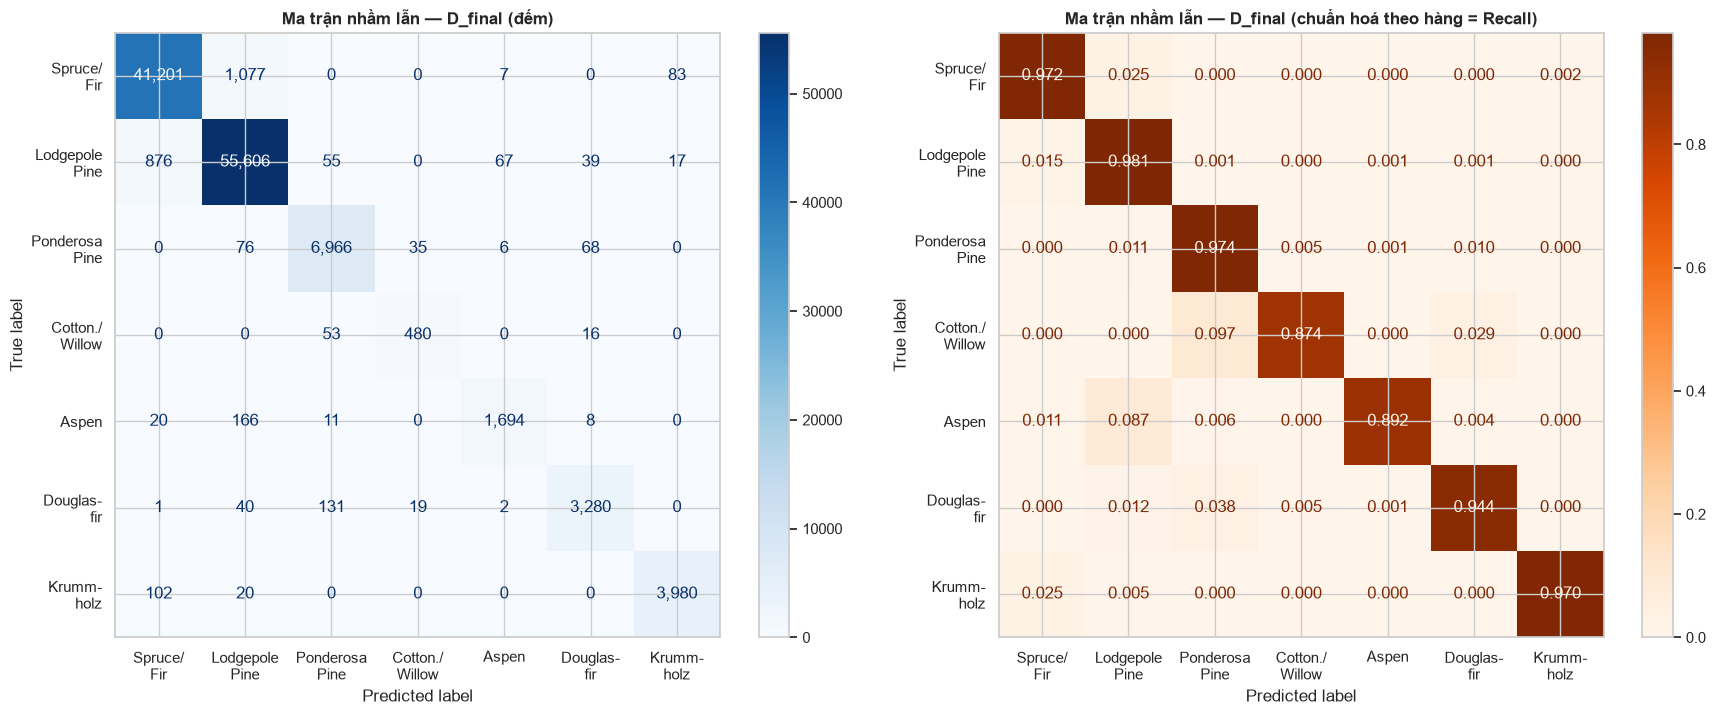

Lỗi chính của từng lớp:
  Lớp 1 (Spruce/Fir): Recall=0.972; nhầm nhiều nhất → Lớp 2 (Lodgepole Pine) (1,077 mẫu)
  Lớp 2 (Lodgepole Pine): Recall=0.981; nhầm nhiều nhất → Lớp 1 (Spruce/Fir) (876 mẫu)
  Lớp 3 (Ponderosa Pine): Recall=0.974; nhầm nhiều nhất → Lớp 2 (Lodgepole Pine) (76 mẫu)
  Lớp 4 (Cottonwood/Willow): Recall=0.874; nhầm nhiều nhất → Lớp 3 (Ponderosa Pine) (53 mẫu)
  Lớp 5 (Aspen): Recall=0.892; nhầm nhiều nhất → Lớp 2 (Lodgepole Pine) (166 mẫu)
  Lớp 6 (Douglas-fir): Recall=0.944; nhầm nhiều nhất → Lớp 3 (Ponderosa Pine) (131 mẫu)
  Lớp 7 (Krummholz): Recall=0.970; nhầm nhiều nhất → Lớp 1 (Spruce/Fir) (102 mẫu)


In [20]:
X_final = build_features(X_final_raw, **FEATURE_SPEC)
y_pred_final = rf_final.predict(X_final)
yf = y_final.values


def bootstrap_ci(y_true, y_pred, n_boot=1000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    accs, f1s = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        ii = rng.integers(0, n, n)
        accs[b] = (y_true[ii] == y_pred[ii]).mean()
        f1s[b] = f1_score(y_true[ii], y_pred[ii], average='macro')
    return np.percentile(accs, [2.5, 97.5]), np.percentile(f1s, [2.5, 97.5])


m_final = eval_preds(yf, y_pred_final)
ci_acc, ci_f1 = bootstrap_ci(yf, y_pred_final)
print(f"D_final: n = {len(yf):,} (lớp 4: {(yf == 4).sum():,})")
print(f"  Accuracy: {m_final['accuracy']:.4f}  [KTC 95%: {ci_acc[0]:.4f}–{ci_acc[1]:.4f}]")
print(f"  Macro-F1: {m_final['macro_f1']:.4f}  [KTC 95%: {ci_f1[0]:.4f}–{ci_f1[1]:.4f}]")
rows = []
for c in range(1, 8):
    k, n = int(((yf == c) & (y_pred_final == c)).sum()), int((yf == c).sum())
    lo, hi = wilson_ci(k, n)
    rows.append({'Lớp': TARGET_NAMES[c - 1], 'n': n, 'Recall': k / n, 'KTC 95% thấp': lo, 'KTC 95% cao': hi})
display(pd.DataFrame(rows).set_index('Lớp'))

print(classification_report(yf, y_pred_final, target_names=TARGET_NAMES, digits=4))

cm = confusion_matrix(yf, y_pred_final, labels=range(1, 8))
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
ConfusionMatrixDisplay(cm, display_labels=SHORT_NAMES).plot(ax=axes[0], cmap='Blues', values_format=',')
axes[0].set_title('Ma trận nhầm lẫn — D_final (đếm)', fontweight='bold')
ConfusionMatrixDisplay(cm / cm.sum(axis=1, keepdims=True), display_labels=SHORT_NAMES).plot(
    ax=axes[1], cmap='Oranges', values_format='.3f')
axes[1].set_title('Ma trận nhầm lẫn — D_final (chuẩn hoá theo hàng = Recall)', fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'eval_confusion_final.png', dpi=150, bbox_inches='tight')
plt.show()

print("Lỗi chính của từng lớp:")
for i in range(7):
    errs = sorted([(cm[i, j], j) for j in range(7) if j != i], reverse=True)
    print(f"  {TARGET_NAMES[i]}: Recall={cm[i, i] / cm[i].sum():.3f}; nhầm nhiều nhất → "
          f"{TARGET_NAMES[errs[0][1]]} ({errs[0][0]:,} mẫu)")

## 10.2. Tầm quan trọng đặc trưng: Gini và Permutation

Permutation importance trên 20,000 mẫu D_val, 5 lần lặp (43s)


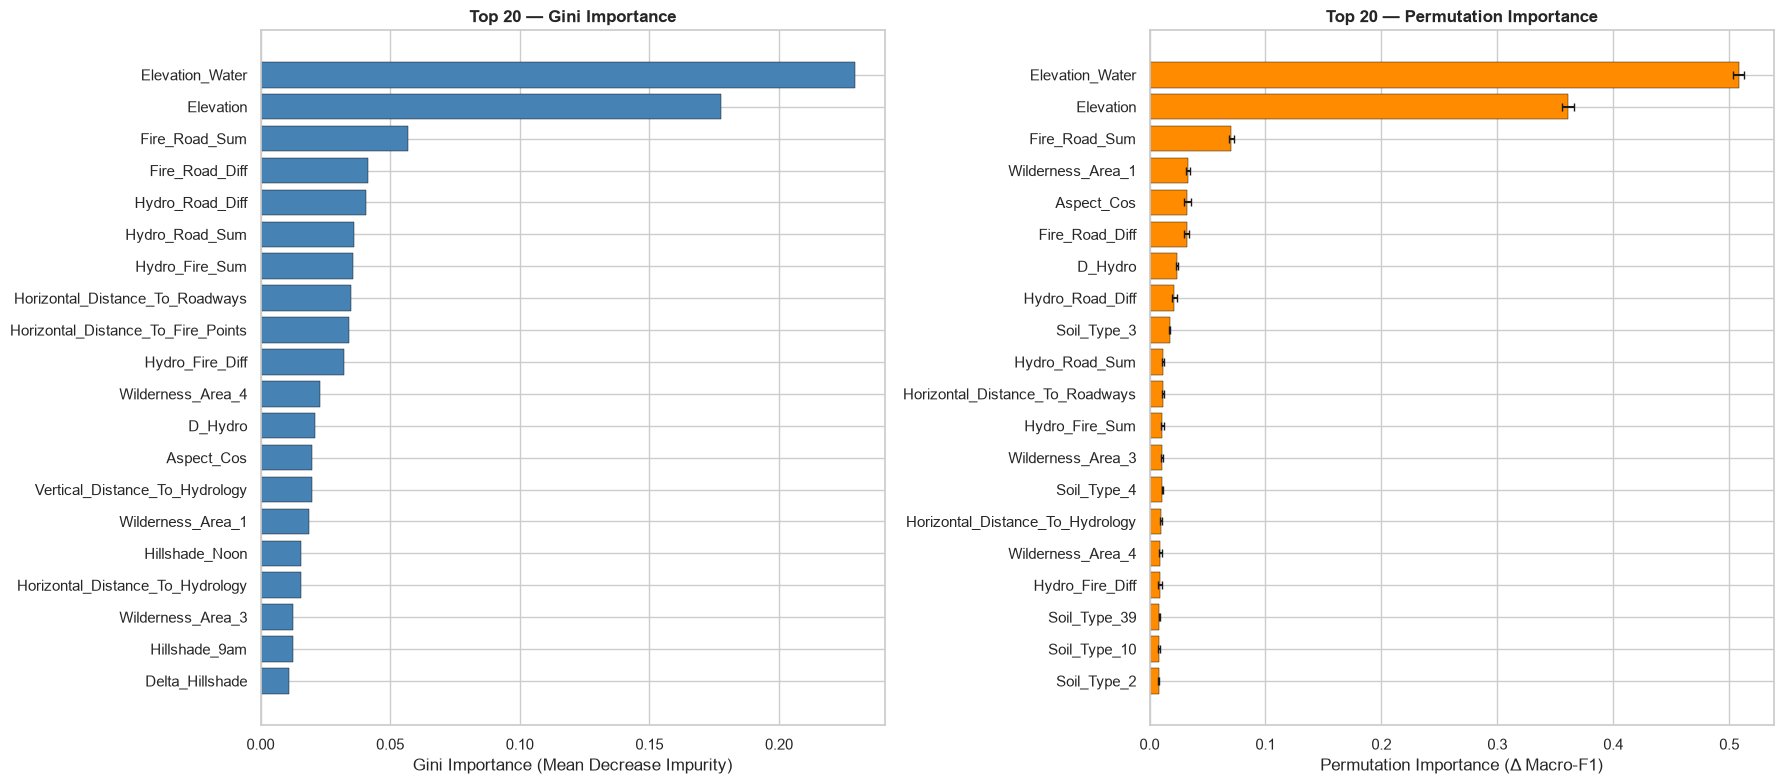

,gini,perm_mean,perm_sd
Elevation_Water,0.2294,0.5082,0.0048
Elevation,0.1775,0.3610,0.0055
Fire_Road_Sum,0.0570,0.0706,0.0024
Wilderness_Area_1,0.0188,0.0336,0.0017
Aspect_Cos,0.0200,0.0326,0.0028
Fire_Road_Diff,0.0413,0.0320,0.0023
D_Hydro,0.0210,0.0235,0.0009
Hydro_Road_Diff,0.0407,0.0215,0.0019
Soil_Type_3,0.0022,0.0173,0.0003
Hydro_Road_Sum,0.0359,0.0121,0.0009


Lưu ý: Gini importance có xu hướng thiên về biến liên tục nhiều giá trị [15]; Permutation importance bị chia sẻ giữa các biến tương quan cao.


In [21]:
idx_pi, _ = train_test_split(np.arange(len(y_val)), train_size=min(20000, len(y_val) - 7),
                             stratify=y_val, random_state=RANDOM_STATE)
t0 = time.time()
# n_jobs=1: với n_jobs > 1, joblib phải pickle cả rừng (hàng trăm MB) sang tiến trình con và có thể thất bại.
# Bản thân rf_final vẫn dự đoán song song (n_jobs=-1, luồng), nên tốc độ không giảm đáng kể.
perm = permutation_importance(rf_final, X_val.iloc[idx_pi], y_val.iloc[idx_pi], n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=1, scoring='f1_macro')
print(f"Permutation importance trên {len(idx_pi):,} mẫu D_val, 5 lần lặp ({time.time() - t0:.0f}s)")
imp = pd.DataFrame({'gini': rf_final.feature_importances_, 'perm_mean': perm.importances_mean,
                    'perm_sd': perm.importances_std}, index=FEATURES).sort_values('perm_mean', ascending=False)
imp.to_csv(TABLE_DIR / 'feature_importance.csv', encoding='utf-8-sig')

top = min(20, len(imp))
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
g = imp.sort_values('gini', ascending=False).head(top)
axes[0].barh(range(top), g['gini'], color='steelblue', edgecolor='black', linewidth=0.3)
axes[0].set_yticks(range(top)); axes[0].set_yticklabels(g.index); axes[0].invert_yaxis()
axes[0].set_xlabel('Gini Importance (Mean Decrease Impurity)')
axes[0].set_title(f'Top {top} — Gini Importance', fontweight='bold')
p = imp.head(top)
axes[1].barh(range(top), p['perm_mean'], xerr=p['perm_sd'], color='darkorange', edgecolor='black',
             linewidth=0.3, capsize=3)
axes[1].set_yticks(range(top)); axes[1].set_yticklabels(p.index); axes[1].invert_yaxis()
axes[1].set_xlabel('Permutation Importance (Δ Macro-F1)')
axes[1].set_title(f'Top {top} — Permutation Importance', fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'eval_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
display(imp.head(15))
print("Lưu ý: Gini importance có xu hướng thiên về biến liên tục nhiều giá trị [15]; "
      "Permutation importance bị chia sẻ giữa các biến tương quan cao.")

---
# BƯỚC 11: E6 — TỔNG QUÁT HOÁ SANG VÙNG CHƯA THẤY (LEAVE-ONE-WILDERNESS-OUT)
> **Câu hỏi**: hiệu năng đo bằng chia ngẫu nhiên (Bước 10) còn lại bao nhiêu khi kiểm thử trên một vùng hoang dã không có trong dữ liệu huấn luyện? Dữ liệu UCI không có toạ độ, nên đây chỉ là **phép kiểm tra thay thế** cho đánh giá theo khối không gian `[16]`.
>
> **Thiết kế**: với mỗi vùng k: huấn luyện trên 3 vùng còn lại (lấy mẫu con phân tầng tới n mẫu), kiểm thử trên **toàn bộ** vùng k, 3 seed.

| Mã | Cấu hình | n huấn luyện | Mục đích |
| :---: | :--- | :---: | :--- |
| **E0** | 54 cột gốc, tham số E0 (`class_weight=None`, mặc định) | như *Cuối* | Kiểm tra đặc trưng sinh thái và tinh chỉnh có giúp chuyển vùng không |
| **Cuối@S15** | đặc trưng + siêu tham số cuối | = S15 | Tách hiệu ứng quy mô dữ liệu |
| **Cuối** | đặc trưng + siêu tham số cuối | min(n của mô hình cuối, số mẫu sẵn có) | Mô hình cuối |
| **Cuối+CW** | như *Cuối*, đổi `class_weight` (None ↔ `balanced_subsample`) | như *Cuối* | Trọng số lớp có giúp chuyển vùng không |

> **Thước đo**: phân bố lớp khác nhau mạnh giữa các vùng (mục 3.5). Báo cáo: (i) Accuracy toàn vùng; (ii) Macro-F1 chỉ trên các lớp **có mặt cả trong huấn luyện và trong vùng kiểm thử**; (iii) tỷ lệ mẫu thuộc lớp chưa từng thấy khi huấn luyện (chắc chắn bị phân loại sai).
>
> **Mốc tham chiếu (chia ngẫu nhiên)**: dự đoán của mô hình cuối (Bước 10) trên các dòng D_final thuộc cùng vùng, tính bằng cùng thước đo và cùng tập lớp.

In [22]:
alt_cw = 'balanced_subsample' if FINAL_PARAMS.get('class_weight') is None else None
E6_CONFIGS = {
    'E0': dict(spec=dict(eco=(), soil='onehot', dist_combo=False), n=len(y_tr),
               params={'n_estimators': N_EST_EXP, 'class_weight': None}),
    'Cuối@S15': dict(spec=FEATURE_SPEC, n=N_EXPLORE, params={**FINAL_PARAMS, 'n_estimators': K_FINAL}),
    'Cuối': dict(spec=FEATURE_SPEC, n=len(y_tr), params={**FINAL_PARAMS, 'n_estimators': K_FINAL}),
    'Cuối+CW': dict(spec=FEATURE_SPEC, n=len(y_tr),
                    params={**FINAL_PARAMS, 'n_estimators': K_FINAL, 'class_weight': alt_cw}),
}


def region_metrics(y_true, y_pred, seen):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    labels = sorted(set(np.unique(y_true)) & set(seen))
    mask = np.isin(y_true, labels)
    return {'acc_all': accuracy_score(y_true, y_pred),
            'macro_f1_seen': f1_score(y_true[mask], y_pred[mask], labels=labels, average='macro'),
            'share_unseen': 1 - mask.mean(), 'labels_seen': ','.join(map(str, labels))}


feat_cache = {}
e6_rows = []
t0 = time.time()
for k in range(1, 5):
    tr_mask = (wa_code != k).values
    y_tr_all, y_te = y_all[tr_mask], y_all[~tr_mask]
    seen = sorted(y_tr_all.unique())

    fin_mask = (wa_code.loc[X_final_raw.index] == k).values
    e6_rows.append({'region': k, 'config': 'Cuối — chia ngẫu nhiên (tham chiếu)', 'seed': -1,
                    'n_train': len(y_tr), 'n_test': int(fin_mask.sum()),
                    **region_metrics(yf[fin_mask], y_pred_final[fin_mask], seen)})
    for name, cfg in E6_CONFIGS.items():
        key = json.dumps(cfg['spec'], default=list)
        if key not in feat_cache:
            feat_cache[key] = build_features(X_all, **cfg['spec'])
        Xf = feat_cache[key]
        n_use = min(cfg['n'], int(tr_mask.sum()))
        for seed in SEEDS:
            pool_idx = np.where(tr_mask)[0]
            if n_use < len(pool_idx):
                pool_idx, _ = train_test_split(pool_idx, train_size=n_use, stratify=y_tr_all, random_state=seed)
            rf_tmp = RandomForestClassifier(random_state=seed, n_jobs=-1, **cfg['params'])
            rf_tmp.fit(Xf.iloc[pool_idx], y_all.iloc[pool_idx])
            e6_rows.append({'region': k, 'config': name, 'seed': seed, 'n_train': n_use,
                            'n_test': int((~tr_mask).sum()),
                            **region_metrics(y_te, rf_tmp.predict(Xf[~tr_mask]), seen)})
            del rf_tmp
            gc.collect()
    print(f"  xong vùng {k} ({WA_NAMES[k]}) — {time.time() - t0:.0f}s")
del feat_cache
gc.collect()

e6_df = pd.DataFrame(e6_rows)
e6_df.to_csv(TABLE_DIR / 'e6_lowo.csv', index=False, encoding='utf-8-sig')

  xong vùng 1 (Rawah) — 363s
  xong vùng 2 (Neota) — 927s
  xong vùng 3 (Comanche Peak) — 1258s
  xong vùng 4 (Cache la Poudre) — 1809s


,region,config,n_train,n_test,acc_mean,acc_sd,f1_seen_mean,f1_seen_sd,share_unseen,labels_seen
0,WA1 (Rawah),Cuối — chia ngẫu nhiên (tham chiếu),348608,52274,0.9774,NaN,0.9647,NaN,0.0000,"1,2,5,7"
1,WA1 (Rawah),E0,320216,260796,0.6070,0.0078,0.3750,0.0053,0.0000,"1,2,5,7"
2,WA1 (Rawah),Cuối@S15,87152,260796,0.6028,0.0010,0.3823,0.0040,0.0000,"1,2,5,7"
3,WA1 (Rawah),Cuối,320216,260796,0.5996,0.0010,0.3822,0.0013,0.0000,"1,2,5,7"
4,WA1 (Rawah),Cuối+CW,320216,260796,0.6064,0.0014,0.3778,0.0025,0.0000,"1,2,5,7"
5,WA2 (Neota),Cuối — chia ngẫu nhiên (tham chiếu),348608,6014,0.9835,NaN,0.9839,NaN,0.0000,"1,2,7"
6,WA2 (Neota),E0,348608,29884,0.5439,0.0111,0.4108,0.0209,0.0000,"1,2,7"
7,WA2 (Neota),Cuối@S15,87152,29884,0.5169,0.0014,0.3890,0.0136,0.0000,"1,2,7"
8,WA2 (Neota),Cuối,348608,29884,0.5141,0.0110,0.3813,0.0117,0.0000,"1,2,7"
9,WA2 (Neota),Cuối+CW,348608,29884,0.5392,0.0052,0.3979,0.0213,0.0000,"1,2,7"


--- Macro-F1 trên các lớp đã thấy ---


region,WA1 (Rawah),WA2 (Neota),WA3 (Comanche Peak),WA4 (Cache la Poudre),TB 4 vùng
config,,,,,
Cuối — chia ngẫu nhiên (tham chiếu),0.9647,0.9839,0.9550,0.9748,0.9696
E0,0.3750,0.4108,0.2579,0.2488,0.3231
Cuối@S15,0.3823,0.3890,0.2618,0.0840,0.2793
Cuối,0.3822,0.3813,0.2513,0.0932,0.2770
Cuối+CW,0.3778,0.3979,0.2444,0.0602,0.2701


--- Accuracy toàn vùng (gồm cả mẫu thuộc lớp chưa thấy) ---


region,WA1 (Rawah),WA2 (Neota),WA3 (Comanche Peak),WA4 (Cache la Poudre),TB 4 vùng
config,,,,,
Cuối — chia ngẫu nhiên (tham chiếu),0.9774,0.9835,0.9711,0.9661,0.9745
E0,0.6070,0.5439,0.5877,0.2295,0.4920
Cuối@S15,0.6028,0.5169,0.5935,0.1066,0.4549
Cuối,0.5996,0.5141,0.5880,0.1141,0.4539
Cuối+CW,0.6064,0.5392,0.5879,0.0864,0.4550


--- Phân rã chênh lệch Macro-F1 (lớp đã thấy) ---


,Suy giảm khi chuyển vùng (tham chiếu − Cuối),Đặc trưng + tinh chỉnh (Cuối − E0),Quy mô dữ liệu (Cuối − Cuối@S15),Trọng số lớp (Cuối+CW − Cuối)
region,,,,
WA1 (Rawah),0.5825,0.0072,-0.0001,-0.0044
WA2 (Neota),0.6026,-0.0295,-0.0078,0.0166
WA3 (Comanche Peak),0.7037,-0.0066,-0.0105,-0.0069
WA4 (Cache la Poudre),0.8816,-0.1556,0.0092,-0.0330
TB 4 vùng,0.6926,-0.0461,-0.0023,-0.0069


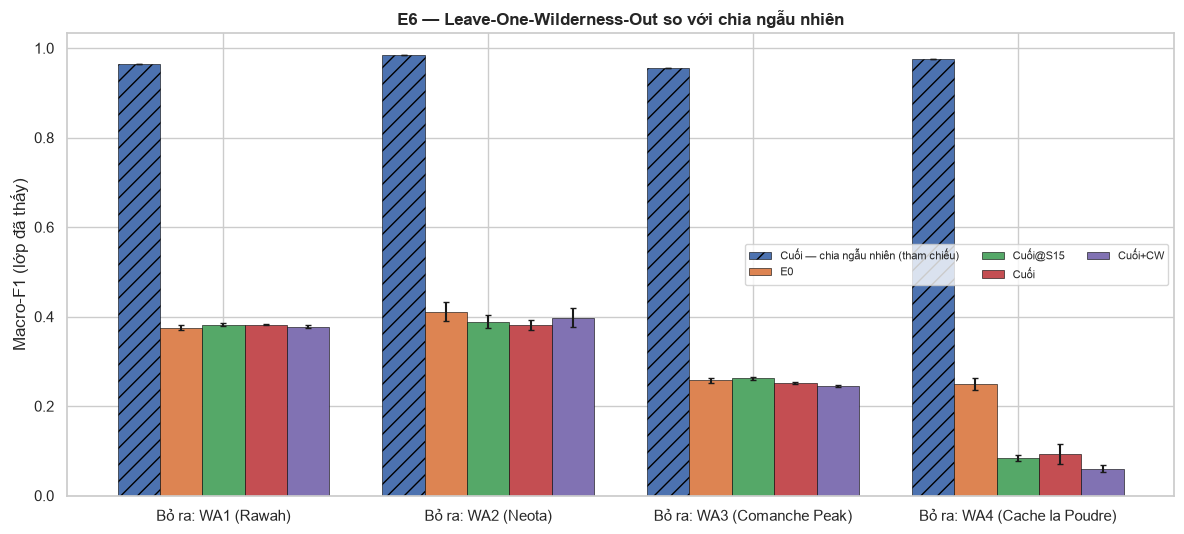

In [23]:
e6_sum = (e6_df.groupby(['region', 'config'], sort=False)
          .agg(n_train=('n_train', 'first'), n_test=('n_test', 'first'),
               acc_mean=('acc_all', 'mean'), acc_sd=('acc_all', 'std'),
               f1_seen_mean=('macro_f1_seen', 'mean'), f1_seen_sd=('macro_f1_seen', 'std'),
               share_unseen=('share_unseen', 'first'), labels_seen=('labels_seen', 'first'))
          .reset_index())
e6_sum['region'] = e6_sum['region'].map(lambda k: f"WA{k} ({WA_NAMES[k]})")
display(e6_sum)

REF = 'Cuối — chia ngẫu nhiên (tham chiếu)'
order = [REF] + list(E6_CONFIGS)
pivot_f1 = e6_sum.pivot(index='config', columns='region', values='f1_seen_mean').loc[order]
pivot_f1['TB 4 vùng'] = pivot_f1.mean(axis=1)
pivot_acc = e6_sum.pivot(index='config', columns='region', values='acc_mean').loc[order]
pivot_acc['TB 4 vùng'] = pivot_acc.mean(axis=1)
print("--- Macro-F1 trên các lớp đã thấy ---")
display(pivot_f1.round(4))
print("--- Accuracy toàn vùng (gồm cả mẫu thuộc lớp chưa thấy) ---")
display(pivot_acc.round(4))
decomp = pd.DataFrame({
    'Suy giảm khi chuyển vùng (tham chiếu − Cuối)': pivot_f1.loc[REF] - pivot_f1.loc['Cuối'],
    'Đặc trưng + tinh chỉnh (Cuối − E0)': pivot_f1.loc['Cuối'] - pivot_f1.loc['E0'],
    'Quy mô dữ liệu (Cuối − Cuối@S15)': pivot_f1.loc['Cuối'] - pivot_f1.loc['Cuối@S15'],
    'Trọng số lớp (Cuối+CW − Cuối)': pivot_f1.loc['Cuối+CW'] - pivot_f1.loc['Cuối'],
})
print("--- Phân rã chênh lệch Macro-F1 (lớp đã thấy) ---")
display(decomp.round(4))

fig, ax = plt.subplots(figsize=(12, 5.5))
regions = [c for c in pivot_f1.columns if c != 'TB 4 vùng']
sub = e6_sum.set_index(['config', 'region'])
w = 0.8 / len(order)
for j, cfg in enumerate(order):
    vals = [sub.loc[(cfg, r), 'f1_seen_mean'] for r in regions]
    errs = [np.nan_to_num(sub.loc[(cfg, r), 'f1_seen_sd']) for r in regions]
    ax.bar(np.arange(len(regions)) + (j - (len(order) - 1) / 2) * w, vals, w, yerr=errs, capsize=2, label=cfg,
           hatch='//' if cfg == REF else None, edgecolor='black', linewidth=0.4)
ax.set_xticks(np.arange(len(regions)))
ax.set_xticklabels([f"Bỏ ra: {r}" for r in regions])
ax.set_ylabel('Macro-F1 (lớp đã thấy)')
ax.set_title('E6 — Leave-One-Wilderness-Out so với chia ngẫu nhiên', fontweight='bold')
ax.legend(fontsize=8, ncol=3)
plt.tight_layout()
plt.savefig(FIG_DIR / 'e6_lowo.png', dpi=150, bbox_inches='tight')
plt.show()

---
# BƯỚC 12: TỔNG KẾT, HẠN CHẾ VÀ ĐẦU VÀO CHO BƯỚC TRÍCH XUẤT LUẬT
> Mọi số liệu dưới đây là **số đo thực nghiệm** của lần chạy này (seed 42, 7, 2024; scikit-learn 1.9.1). Mục 1–3 đo trên D_val, mục 4 trên D_final (đánh giá một lần), mục 5 theo giao thức E6.

## 1. Pha khảo sát trên S15 (E0–E3; 87.152 mẫu huấn luyện, 100 cây)
| Thí nghiệm | Kết quả chính (Macro-F1 TB ± SD) | Quyết định |
| :--- | :--- | :--- |
| **E0/E1** — trọng số lớp | `None` 0,8432 ± 0,0019; `balanced` 0,8471 ± 0,0012; `balanced_subsample` 0,8412 ± 0,0012. `balanced` nâng Recall lớp 5 từ 0,55 lên 0,79, nhưng Precision lớp 4 giảm từ 0,836 xuống 0,818 | `balanced` |
| **E2** — đặc trưng sinh thái | Gốc 54 cột 0,8471 → thêm 4 nhóm 0,8499 (+0,0028). Bỏ `Elevation_Water` −0,0167, nhóm có đóng góp lớn nhất. Bỏ `Aspect_Trig` (+0,0058) hoặc `Delta_Hillshade` (+0,0033) cho F1 **cao hơn**. Thêm tổ hợp khoảng cách: 0,8901 (+0,0402) | 4 nhóm + tổ hợp khoảng cách (65 cột) |
| **E3** — thổ nhưỡng | One-Hot 0,8901 ± 0,0019; Code 0,8862; Zone 0,8852; Code + Zone 0,8867. One-Hot cao hơn các phương án gộp khoảng 2 SD | One-Hot |

- **Giả thuyết "pha loãng" của One-Hot** không được ủng hộ trong thiết lập này (`max_depth=None`, có tổ hợp khoảng cách): gộp 40 cột đất thành mã số làm F1 giảm thay vì tăng.
- **Hạn chế của thiết kế tuần tự**: E2 chỉ bỏ từng nhóm khi chưa có tổ hợp khoảng cách. Tổ hợp "tổ hợp khoảng cách + bỏ `Aspect_Trig`/`Delta_Hillshade`" chưa được thử; đây là ứng viên cho một vòng ablation tiếp theo.

## 2. E4 — Quy mô dữ liệu
- Với `max_depth=None`, Macro-F1 tăng từ 0,8896 (25% D_pool ≈ S15) lên 0,9397 ± 0,0009 (100% D_pool, 348.608 mẫu), tức +0,050. Đường cong vẫn còn dốc ở đoạn 75% → 100% (+0,008), nên chưa quan sát thấy điểm bão hoà.
- `max_depth=20` cho F1 thấp hơn ở mọi mức dữ liệu, nhưng Recall lớp 4 và lớp 5 cao hơn (ở 100%: 0,902 so với 0,881 và 0,967 so với 0,945). Giới hạn độ sâu cùng `class_weight='balanced'` dịch biên quyết định về phía các lớp hiếm, đổi lại Precision thấp hơn.

## 3. E5 — Siêu tham số và mô hình cuối
- `criterion='entropy'` cho F1 cao hơn `gini` ở cả 4 mức `max_features`. `max_features=0.5` và `0.35` ngang nhau ở giai đoạn 1 (0,9450).
- Ở giai đoạn 2, `class_weight=None` cho F1 cao hơn `balanced` khi dùng toàn bộ D_pool (0,9519 so với 0,9450), tức là ngược với lựa chọn của E1 trên S15. Lựa chọn trọng số lớp **phụ thuộc quy mô dữ liệu**.
- Cấu hình cuối: `max_depth=None, max_features=0.5, criterion='entropy', min_samples_leaf=1, class_weight=None`, Macro-F1 trên D_val 0,9529 ± 0,0011.
- **Đánh đổi cần lưu ý**: `balanced_subsample, min_samples_leaf=2` có F1 thấp hơn 0,0039 nhưng Recall lớp 4 cao hơn (0,901 ± 0,007 so với 0,893 ± 0,004). Nếu đề tài ưu tiên độ nhạy của lớp 4 hơn Macro-F1, nên chọn cấu hình này.
- Số cây: F1 trên D_val tăng 0,0010 từ 150 lên 300 cây, nhỏ hơn 1 SD, nên **chọn 150 cây** (≈ 25.000 nút/cây; file 72 MB).

## 4. Đánh giá một lần trên D_final (n = 116.202; lớp 4 = 549)
| Chỉ số | Ngưỡng kỳ vọng (docs) | Số đo [KTC 95%] |
| :--- | :---: | :---: |
| Accuracy | ≥ 0,88 | 0,9742 [0,9733–0,9751] |
| Macro-F1 | ≥ 0,78 | 0,9510 [0,9476–0,9545] |
| Recall lớp 4 | ≥ 0,75 | 0,874 [0,844–0,900] |
| Recall lớp 5 (thấp thứ hai) | — | 0,892 [0,877–0,905] |

- Lỗi chủ yếu nằm ở cặp lớp 1 ↔ 2 (Spruce/Fir ↔ Lodgepole Pine; 1.077 và 876 mẫu) và lớp 4 → 3 (53 mẫu).
- **Tầm quan trọng (Permutation, D_val)**: `Elevation_Water` (0,508) và `Elevation` (0,361) chiếm ưu thế. Xếp sau là `Fire_Road_Sum` (0,071), `Wilderness_Area_1`, `Aspect_Cos`, `Fire_Road_Diff`. Ba trong sáu đặc trưng đứng đầu gắn với vị trí: hai tổ hợp khoảng cách tới đường và điểm cháy, và mã vùng.

## 5. E6 — Vùng chưa thấy (Macro-F1 trên các lớp đã thấy, TB 4 vùng, 3 seed)
| Cấu hình | WA1 | WA2 | WA3 | WA4 | TB |
| :--- | :---: | :---: | :---: | :---: | :---: |
| Cuối — chia ngẫu nhiên (tham chiếu) | 0,965 | 0,984 | 0,955 | 0,975 | 0,970 |
| E0 (54 cột gốc, mặc định) | 0,375 | 0,411 | 0,258 | 0,249 | **0,323** |
| Cuối@S15 | 0,382 | 0,389 | 0,262 | 0,084 | 0,279 |
| Cuối | 0,382 ± 0,001 | 0,381 ± 0,012 | 0,251 ± 0,002 | 0,093 ± 0,022 | **0,277** |
| Cuối+CW (`balanced_subsample`) | 0,378 | 0,398 | 0,244 | 0,060 | 0,270 |

- **Suy giảm mạnh khi chuyển vùng**: từ 0,970 xuống 0,277 (−0,69). Accuracy trung bình 4 vùng còn 0,45.
- **Các lựa chọn ở E2–E5 không cải thiện, và có xu hướng làm giảm, khả năng chuyển vùng**: mô hình cuối thấp hơn E0 trung bình 0,046. Phần lớn chênh lệch đến từ WA4 (0,093 so với 0,249). Ở WA1–WA3 chênh lệch nằm trong khoảng ±0,03. Tăng quy mô dữ liệu (Cuối − Cuối@S15: −0,002) và đổi trọng số lớp (−0,007) không tạo khác biệt đáng kể.
- WA4: 7,4% mẫu thuộc lớp 4 (chỉ có ở vùng này) chắc chắn bị phân loại sai; con số này được báo cáo riêng và không tính vào Macro-F1 trên các lớp đã thấy.

**Diễn giải**:
- Kết quả phù hợp với giả thuyết rằng phần lớn mức tăng trên D_final đến từ việc khai thác mẫu lân cận trong cùng vùng: các ô 30 m liền kề, và các đặc trưng gắn với vị trí (khoảng cách tới đường, tới điểm cháy, các tổ hợp của chúng, mã vùng). Mức tăng có vẻ không đến từ quy luật sinh thái tổng quát hơn. Việc mô hình cuối kém E0 ở WA4, đi cùng tầm quan trọng cao của `Fire_Road_*`, củng cố giả thuyết này nhưng **chưa chứng minh** nó.
- E6 gộp hai yếu tố: (i) tự tương quan không gian; (ii) dịch chuyển phân bố thật giữa các vùng (tỷ lệ lớp, dải cao độ, loại đất; cột `Wilderness_Area_k` của vùng bị bỏ ra luôn bằng 0 khi huấn luyện). E6 vì vậy là cận dưới khắt khe, chưa tách được phần đóng góp của từng yếu tố.

## 6. Hạn chế
1. **Phạm vi áp dụng**: các chỉ số ở mục 1–4 chỉ đúng cho dự đoán bên trong 4 vùng nghiên cứu với phép chia ngẫu nhiên (xem mục 5).
2. Độ lệch chuẩn qua seed phản ánh biến thiên do lấy mẫu con và do RF, **không** phản ánh biến thiên do chọn D_val (D_val cố định).
3. Tìm kiếm tuần tự (E1 → E2 → E3 → E4 → E5) không quét đủ tương tác. Ví dụ, lựa chọn `class_weight` ở E1 bị đảo ngược ở E5 khi quy mô dữ liệu thay đổi.
4. Các tổ hợp khoảng cách là heuristic thực hành, chưa có cơ sở bình duyệt, và gắn với vị trí. Nếu chúng xuất hiện trong luật của cây đại diện thì cần biện luận ý nghĩa sinh thái.
5. Rừng sâu (≈ 25.000 nút/cây, 65 cột) có thể khó xấp xỉ bằng một cây đại diện độ sâu 3–6, nên Fidelity có thể thấp. `[CẦN ĐO]` ở E7.

## 7. Đầu vào cho bước trích xuất luật (E7) và việc tiếp theo
- **Mô hình chủ**: `models/rf_covertype_final.joblib`. Cấu hình và danh sách 65 đặc trưng ở `models/rf_final_config.json`; tái tạo đặc trưng bằng `build_features(df, **FEATURE_SPEC)`.
- **Chỉ số phân chia**: `models/splits.npz`. Dùng `idx_val` (D_val, rời tập huấn luyện RF) làm bể truy vấn để huấn luyện cây đại diện theo dự đoán của RF; dùng `idx_final` (D_final) để đo Fidelity và Accuracy của cây.
- **[GIẢ THUYẾT] cần kiểm chứng trước hoặc song song với E7**: loại các đặc trưng gắn với vị trí (`Horizontal_Distance_To_Roadways`, `Horizontal_Distance_To_Fire_Points`, các tổ hợp của chúng, và có thể cả `Wilderness_Area_*`), rồi chạy lại E6. Mục tiêu là đo đánh đổi giữa hiệu năng trong vùng và khả năng chuyển vùng, và tìm một mô hình chủ cho luật có ý nghĩa sinh thái rõ hơn.